# Imports

In [1]:
import os
import pickle
import pandas as pd
import numpy as np
import collections
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from cycler import cycler
import numpy as np
import pylab
import FlowCal
import copy
from matplotlib.lines import Line2D
import warnings
import corner
from matplotlib.colors import ListedColormap

import emcee

# Set default parameters for plots
sns.set_context("talk", font_scale=1, rc={"lines.linewidth": 2.0, 'lines.markersize': 5})
sns.set_style("ticks")
sns.set_style({"xtick.direction": "in","ytick.direction": "in"})
mpl.rc('axes', prop_cycle=(cycler('color', ['r', 'k', 'b','g','y','m','c']) ))
mpl.rc('text', usetex=False)
#mpl.rc('font',**{'family':'sans-serif','sans-serif':['HelveticaNeueThin']})
#plt.tick_params(top=False, bottom=False, right=False, left=False)
tw = 1.5
sns.set_style({"xtick.major.size": 6, "ytick.major.size": 6,
               "xtick.minor.size": 4, "ytick.minor.size": 4,
               'axes.labelsize': 24,
               'xtick.major.width': tw, 'xtick.minor.width': tw,
               'ytick.major.width': tw, 'ytick.minor.width': tw})

mpl.rc('xtick', labelsize=18) 
mpl.rc('ytick', labelsize=18)
mpl.rc('axes', linewidth=1.75)
plt.gcf().subplots_adjust(bottom=0.15)
sns.set_style({'axes.labelsize': 24, 'axes.titlesize': 24})

# %matplotlib inline
# warnings.filterwarnings(action='once')
warnings.filterwarnings('ignore')

<Figure size 640x480 with 0 Axes>

# Function Setup

In [2]:
# gRNA properties

# This is a new PAM dict for the DP strains.
# It uses the midpoint of the combined dCas9:PhlF footprint (66bp), which is
# the 3rd bp after/before the side of the PhlO site closest to the PAM.
# Positions are given in absolute values, as in 0 is immediately before +1.
# To convert to genomic position, subtract 1 from all negative values.
PAM_dict_DP = {'g1': -49,
               'g2': -33,
               'g3': 12,
               'g5': 36,
               'g16': 94,
               'g17': 115,
              }

# This is a new PAM dict for the P strains. It uses the central bp of
# the 30bp PhlO site, which I take to be the 16th position.
# (this is the 15th position when it is PhlOrc)
# Positions are given in absolute values, as in 0 is immediately before +1.
# To convert to genomic position, subtract 1 from all negative values.
PAM_dict_P = {'g1': -31,
              'g2': -51,
              'g3': 30,
              'g5': 18,
              'g16': 112,
              'g17': 97,
             }

strand_dict = {'g1': 'right',
               'g2': 'left',
               'g3': 'right',
               'g4': 'right',
               'g5': 'left',
               'g6': 'right',
               'g8': 'right',
               'g9': 'left',
               'g10': 'left',
               'g11': 'right',
               'g12': 'right',
               'g13': 'left',
               'g15': 'left',
               'g16': 'right',
               'g17': 'left',
              }

def strand_to_footprint(PAM, strand):
    '''
    PAM is an integer.
    strand is a string that is 'right' or 'left'.
    '''
    if strand == 'right':
        rightwindow = PAM + 8 # 9bp overhang beyond gRNA. N in NGG already included.
        leftwindow = PAM - 20 - 1 #1bp overhang beyond gRNA.
    elif strand == 'left':
        rightwindow = PAM + 20 + 1
        leftwindow = PAM - 8
    else:
        raise('Problem with strand')
    return leftwindow, rightwindow

In [3]:
# Helper functions

def Hill_rep_fun(x, params):
    '''
    Hill repression function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def Hill_act_fun(x, params):
    '''
    Hill activation function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b * np.exp(n*(np.log(x) - np.log(K))) / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def symlog_transform(x, linthresh=1.0):
    return np.sign(x) * (np.log1p(np.abs(x / linthresh)))
def symlog_inverse(y, linthresh=1.0):
    return np.sign(y) * linthresh * (np.expm1(np.abs(y)))

def log_lognormal(x, mu, sigma):
    '''
    Returns the log prior for a lognormal distribution.
    Takes x as input in non-log-scaled value.
    To obtain a median of M for the distribution, must input mu = ln(M).
    '''
    return -np.log(x) - np.log(sigma) - 0.5 * np.log(2 * np.pi) - ((np.log(x) - mu) ** 2) / (2 * sigma**2)


In [4]:
# functions for emcee

def log_prior(theta, prior_params):     
    '''
    Lognormal priors for all four parameters.
    '''
    b, a, K, n = theta
    b_params, a_params, K_params, n_params = prior_params
    mub, sigmab = b_params
    mua, sigmaa = a_params
    muK, sigmaK = K_params
    mun, sigman = n_params
    
    # log-normal prior on beta
    logbprior = -np.log(b) - np.log(sigmab) - 0.5 * np.log(2 * np.pi) - ((np.log(b) - mub) ** 2) / (2 * sigmab**2)
    # log-normal prior on alpha
    logaprior = -np.log(a) - np.log(sigmaa) - 0.5 * np.log(2 * np.pi) - ((np.log(a) - mua) ** 2) / (2 * sigmaa**2)
    # log-normal prior on K
    logKprior = -np.log(K) - np.log(sigmaK) - 0.5 * np.log(2 * np.pi) - ((np.log(K) - muK) ** 2) / (2 * sigmaK**2)
    # log-normal prior on n
    lognprior =  -np.log(n) - np.log(sigman) - 0.5 * np.log(2 * np.pi) - ((np.log(n) - mun) ** 2) / (2 * sigman**2)
    
    return logbprior + logaprior + logKprior + lognprior

def log_likelihood(theta, x, y):
    '''
    Model is a Hill repression function, with output in ln() scale.
    This requires data, y, to also be in ln() scale.
    '''
    b, a, K, n = theta

    model = np.log(b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a) # <- this is ln(Hill rep function), written in numerically stable form
    
    cost = - np.linalg.norm(y - model) # <- Make sure the model and the data are appropriately log-transformed   
    cost_progress.append(cost)
    return cost


def log_probability(theta, x, y, prior_params):
    lp = log_prior(theta, prior_params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y)

In [5]:
def make_2D_plot(fcs_dict_ls, media, grna, rep, atcs, fill=False, savefig=False, linthresh=1, filetype='png'):
    '''
    Inputs:
        fcs_dict_ls: list of gated fcs dictionaries arranged by replicate
        media: string, 'M9' or 'CL'
        grna: string, 'gN' where N is an integer
        rep: integer, 1,2,3
        atcs: list of strings of labels of atc concentrations (ng/mL).
              First entry is 'Blank'.
        fill: Boolean to determine if margin KDEs are filled or not.
    '''
    cmap = plt.get_cmap('viridis',len(atcs)-1)
    
    fcs_gated_dict = fcs_dict_ls[rep-1]
    
    plt.figure(figsize=(4,4))
    g = sns.JointGrid(space=0)

    med_gfps = np.empty(len(atcs))
    med_rfps = np.empty(len(atcs))
    for n in range(len(atcs)):
        fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n]]
        gfps = np.array(fcs[:,5])
        rfps = np.array(fcs[:,7])
        
        # calculate median gfp, rfp values for later
        med_gfps[n] = np.median(gfps)
        med_rfps[n] = np.median(rfps)
    
        # transform gfp, rfp values into symlog space
        symlog_gfps = symlog_transform(gfps, linthresh=linthresh)
        symlog_rfps = symlog_transform(rfps, linthresh=linthresh)
    
        # start filling plots
        if n==0:
            color = 'grey'
        else:
            color = cmap(n-1)
            
        sns.scatterplot(x=rfps, y=gfps, color=color,
                        s=2, alpha=0.1, ax=g.ax_joint,
                        legend=False)
        
        rfp_kde = stats.gaussian_kde(symlog_rfps)
        rfp_xrange = np.linspace(min(symlog_rfps), max(symlog_rfps), 1000)
        rfp_kde_y = rfp_kde(rfp_xrange)
        g.ax_marg_x.plot(symlog_inverse(rfp_xrange, linthresh=linthresh), rfp_kde_y, c=color)
        if fill:
            g.ax_marg_x.fill_between(symlog_inverse(rfp_xrange, linthresh=linthresh), np.zeros(len(rfp_kde_y)), rfp_kde_y, color=color, alpha=0.2)
        
        gfp_kde = stats.gaussian_kde(symlog_gfps)
        gfp_xrange = np.linspace(min(symlog_gfps), max(symlog_gfps), 1000)
        gfp_kde_y = gfp_kde(gfp_xrange)
        g.ax_marg_y.plot(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), c=color)
        if fill:
            g.ax_marg_y.fill_between(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), np.zeros(len(gfp_kde_y)), color=color, alpha=0.2)
    
    # plot medians
    g.ax_joint.scatter(med_rfps[0], med_gfps[0], c='k')
    g.ax_joint.scatter(med_rfps[1:], med_gfps[1:], c='r')
    
    g.ax_joint.set_xscale('symlog', linthresh=linthresh)
    g.ax_joint.set_yscale('log')
    g.ax_joint.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_marg_x.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_joint.set_ylim((1e0,5e6))
    g.ax_joint.set_xlim((-2e1,2e3))
    # g.ax_joint.set_ylim(bottom=1e0)
    g.ax_joint.set_xlabel('Repressor:RFP')
    g.ax_joint.set_ylabel('GFP')
    # g.ax_marg_x.set_title(grna + ', ' + media + ', Rep '+str(rep))
    print(grna + ', ' + media + ', Rep '+str(rep))
    
    if savefig:
        filename = savefig + '_' + grna + '_' + media + '_rep' + str(rep) + '_2Dplot.'+ filetype
        plt.savefig('./figs/2Dplots/'+filename, bbox_inches='tight')

    plt.show()

# Unpickle FCS data

In [6]:
with open('./pickles/250501_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_1 = pickle.load(f)
f.close()

with open('./pickles/250509_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_2 = pickle.load(f)
f.close()

with open('./pickles/250511_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_3 = pickle.load(f)
f.close()

Reformat data so it follows the same format as the dCas9 gates

In [7]:
fcs_dict_ls = [fcs_gated_dict_1,
               fcs_gated_dict_2,
               fcs_gated_dict_3,
              ]

fcs_dict_ls_P = []
fcs_dict_ls_D = []
for fcs_dict in fcs_dict_ls:
    gated_dict_P_temp = dict()
    gated_dict_D_temp = dict()
    for key in fcs_dict.keys():
        media = key[:2]
        protein = key[3]
        rest = key[4:]
        
        if protein == 'P':
            gated_dict_P_temp[media+rest] = fcs_dict[key]
        elif protein == 'D':
            gated_dict_D_temp[media+rest] = fcs_dict[key]
        else:
            print('ERROR!')

    fcs_dict_ls_P.append(gated_dict_P_temp)
    fcs_dict_ls_D.append(gated_dict_D_temp)

# Plotting and analysis

## Single-cell GFP/RFP plots

Supplemental Figs 14-24

In [8]:
plot_inds_cl = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9 = [0, 0.2, 0.43, 0.93, 2, 2.6, 3.5, 6.3, 11.3, 20, 100]

plot_inds_ls = [[plot_inds_m9, plot_inds_cl],
                [plot_inds_m9, plot_inds_cl],
                [plot_inds_m9, plot_inds_cl],
               ]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

atcs_ls = [[atcs_m9, atcs_cl],
           [atcs_m9, atcs_cl],
           [atcs_m9, atcs_cl],
          ]

medias = ['M9', 'CL']
reps = [1,2,3]
grnas = ['g1','g2','g3','g5','g16','g17']

g1, M9, Rep 1


<Figure size 400x400 with 0 Axes>

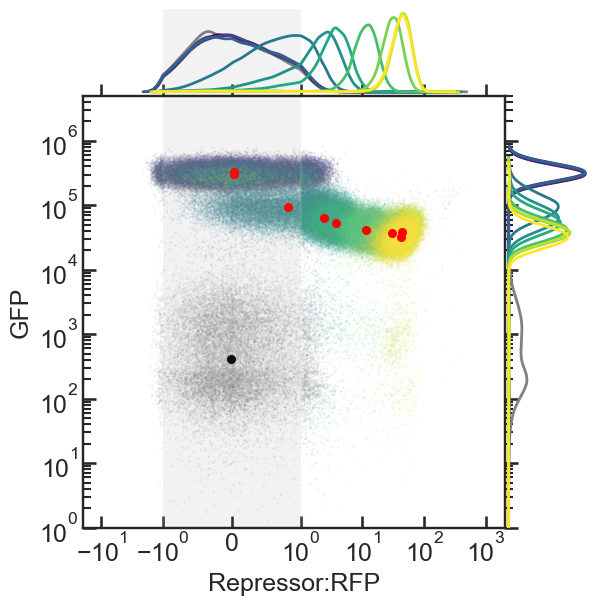

g1, M9, Rep 2


<Figure size 400x400 with 0 Axes>

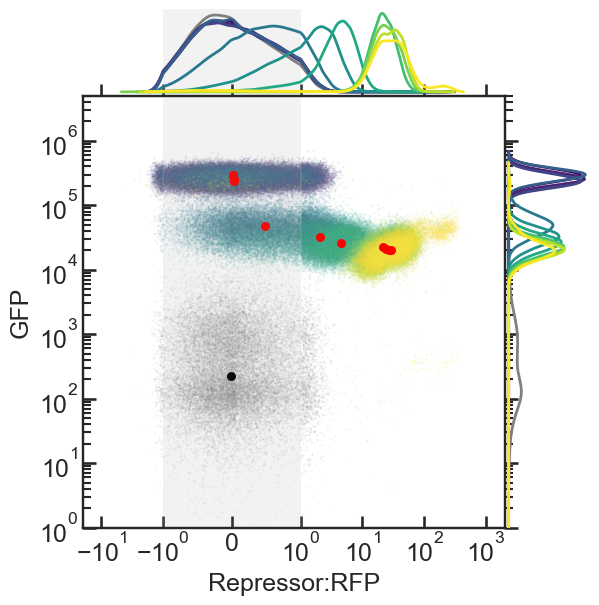

g1, M9, Rep 3


<Figure size 400x400 with 0 Axes>

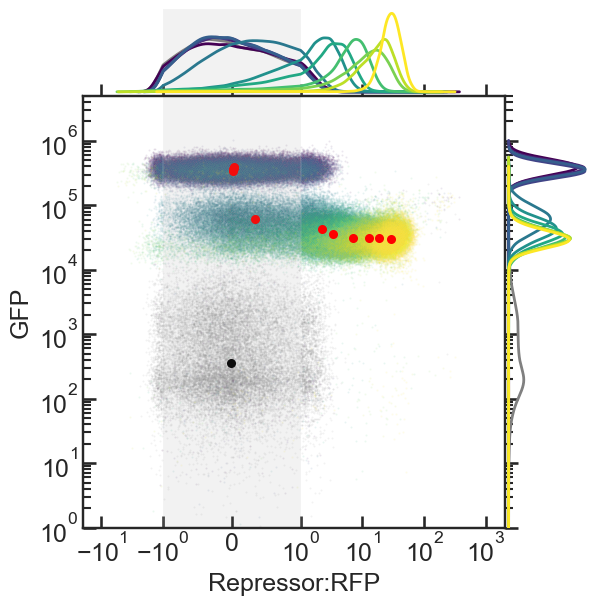

g1, CL, Rep 1


<Figure size 400x400 with 0 Axes>

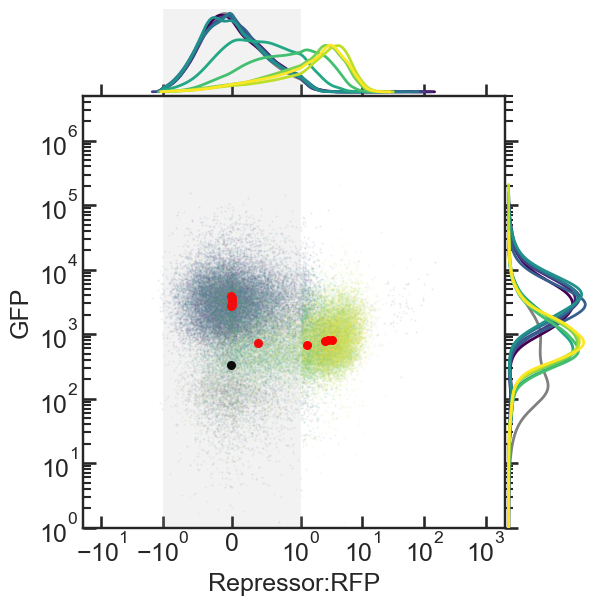

g1, CL, Rep 2


<Figure size 400x400 with 0 Axes>

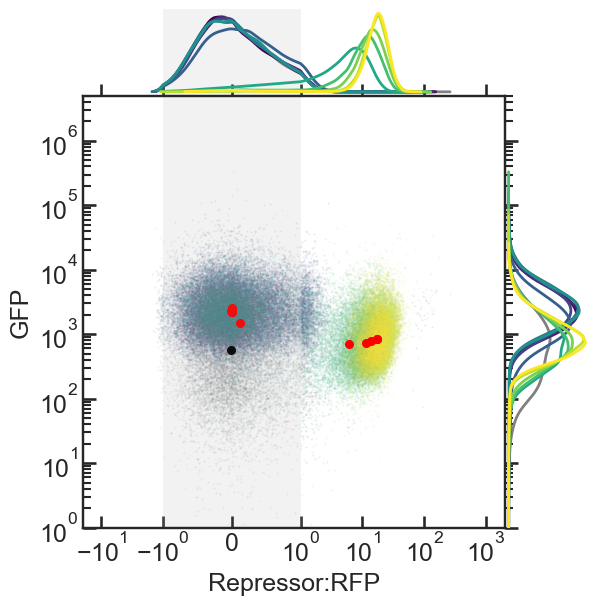

g1, CL, Rep 3


<Figure size 400x400 with 0 Axes>

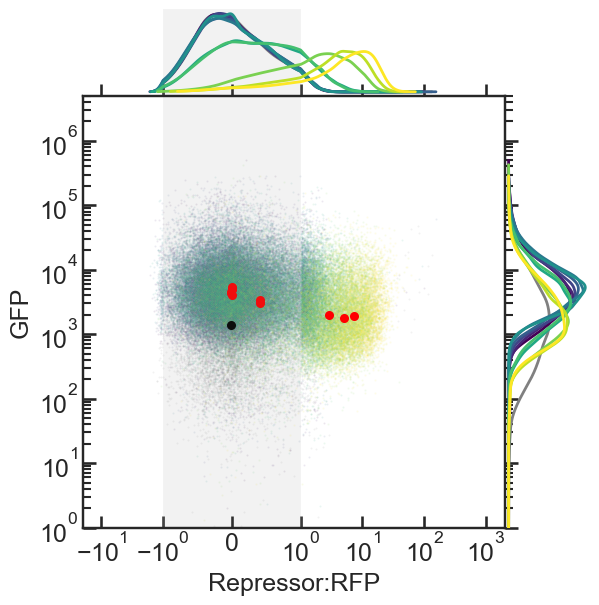

g2, M9, Rep 1


<Figure size 400x400 with 0 Axes>

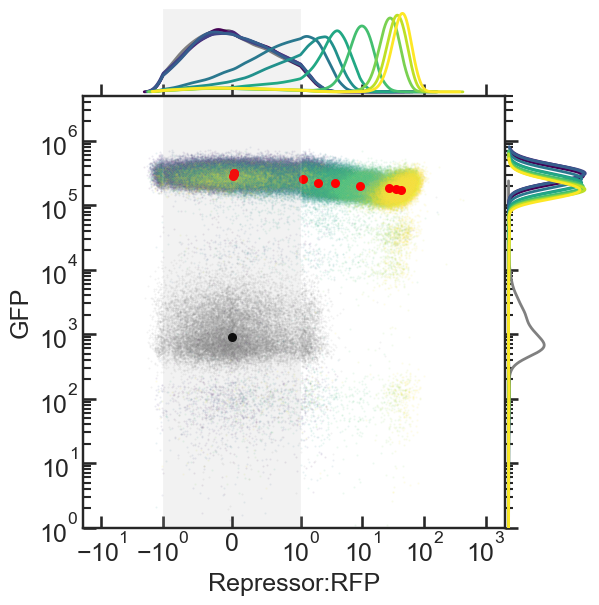

g2, M9, Rep 2


<Figure size 400x400 with 0 Axes>

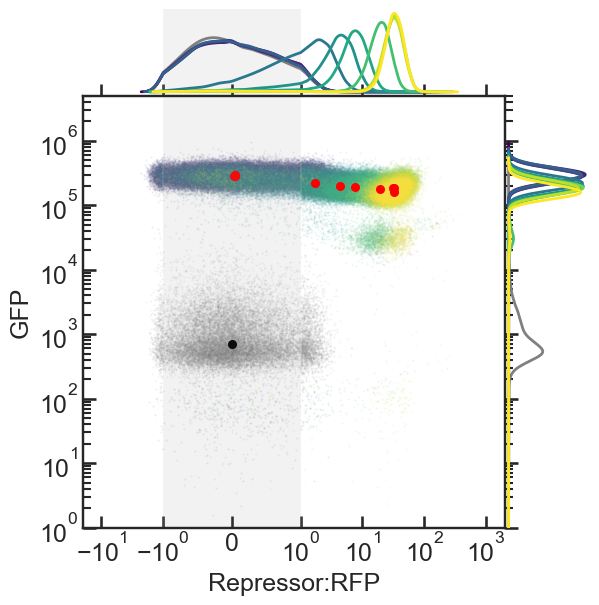

g2, M9, Rep 3


<Figure size 400x400 with 0 Axes>

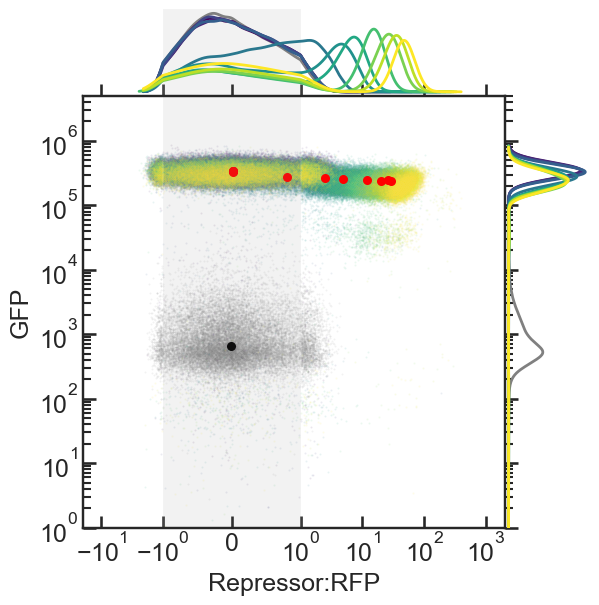

g2, CL, Rep 1


<Figure size 400x400 with 0 Axes>

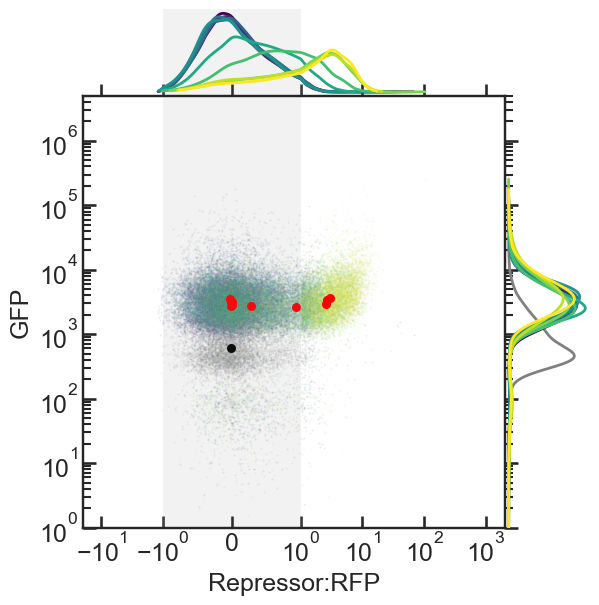

g2, CL, Rep 2


<Figure size 400x400 with 0 Axes>

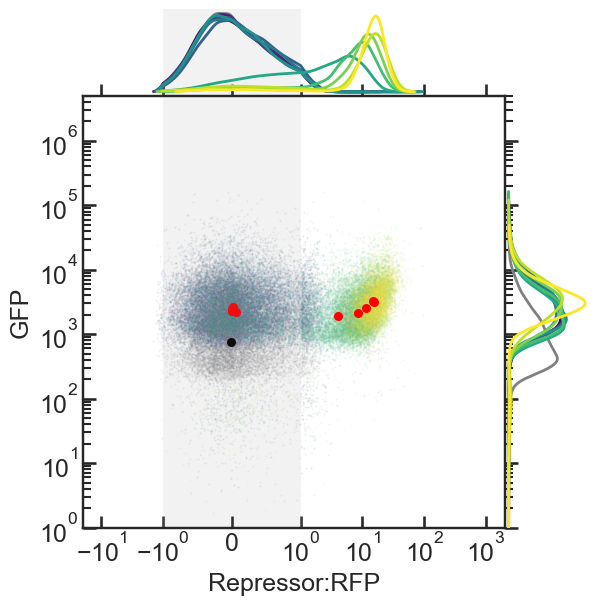

g2, CL, Rep 3


<Figure size 400x400 with 0 Axes>

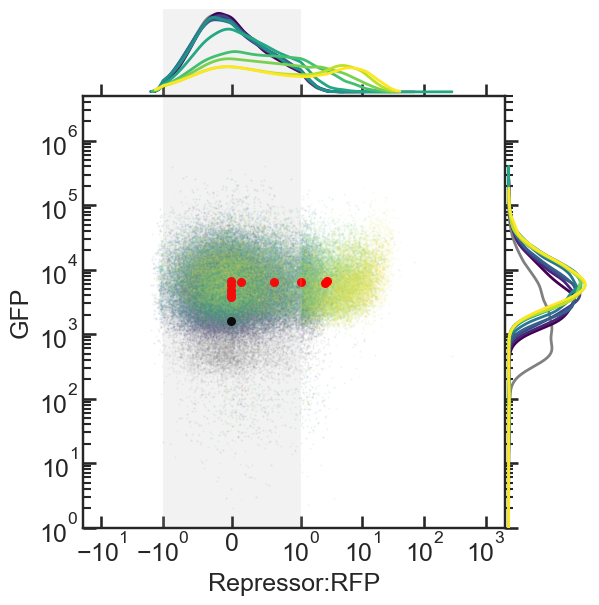

g3, M9, Rep 1


<Figure size 400x400 with 0 Axes>

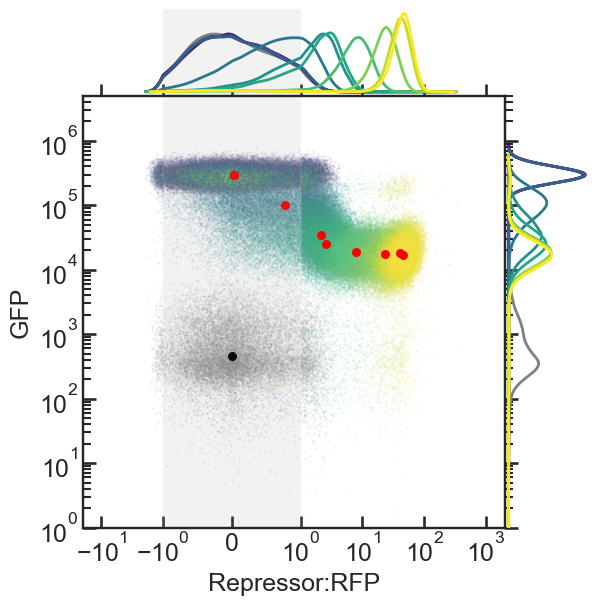

g3, M9, Rep 2


<Figure size 400x400 with 0 Axes>

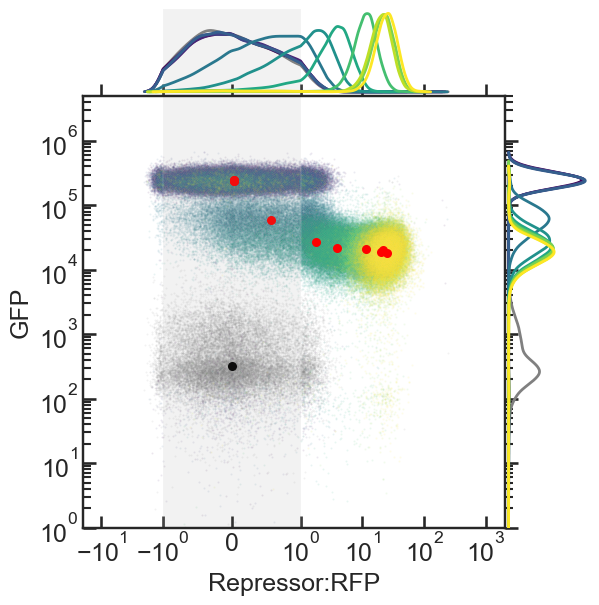

g3, M9, Rep 3


<Figure size 400x400 with 0 Axes>

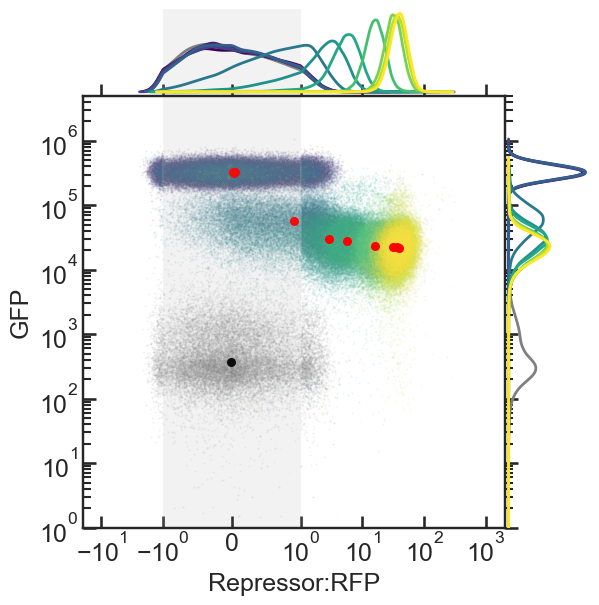

g3, CL, Rep 1


<Figure size 400x400 with 0 Axes>

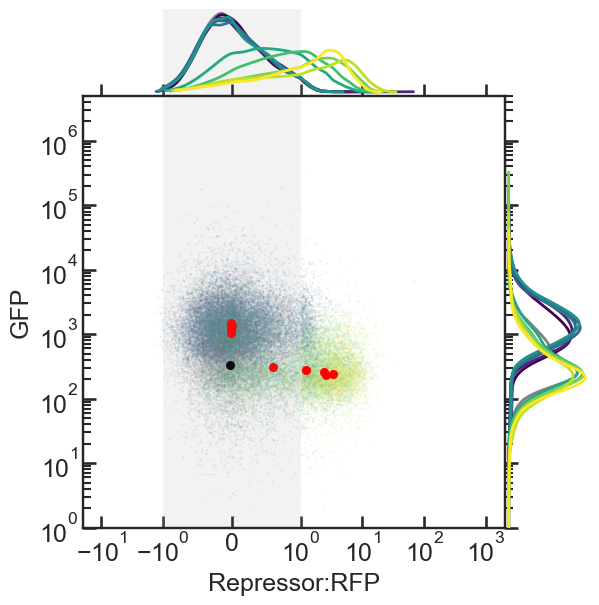

g3, CL, Rep 2


<Figure size 400x400 with 0 Axes>

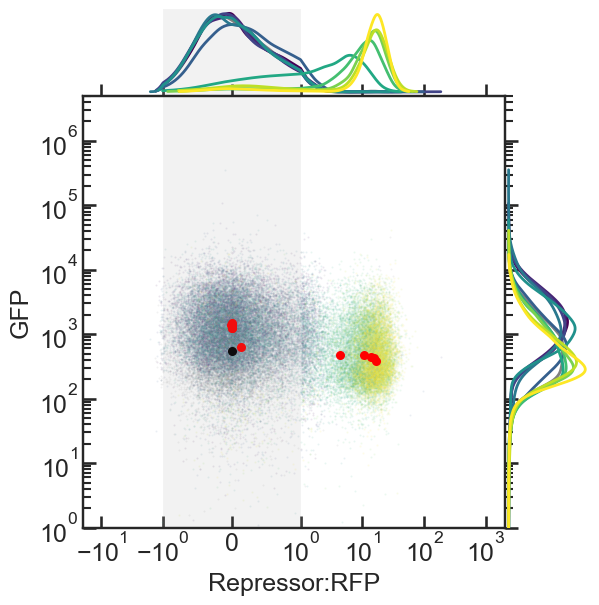

g3, CL, Rep 3


<Figure size 400x400 with 0 Axes>

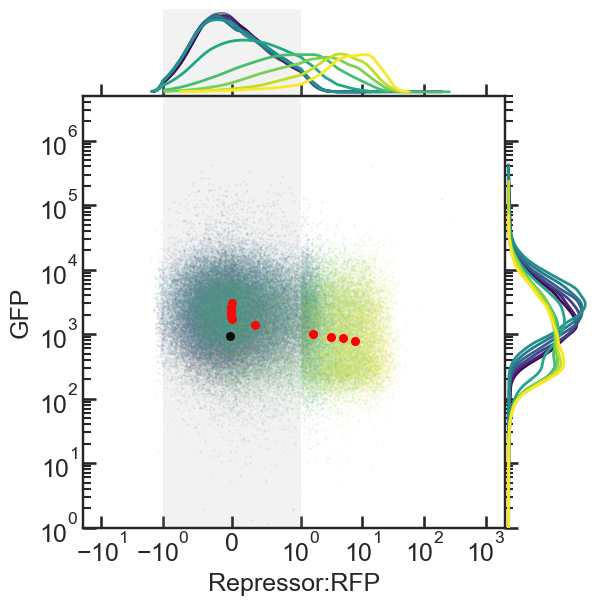

g5, M9, Rep 1


<Figure size 400x400 with 0 Axes>

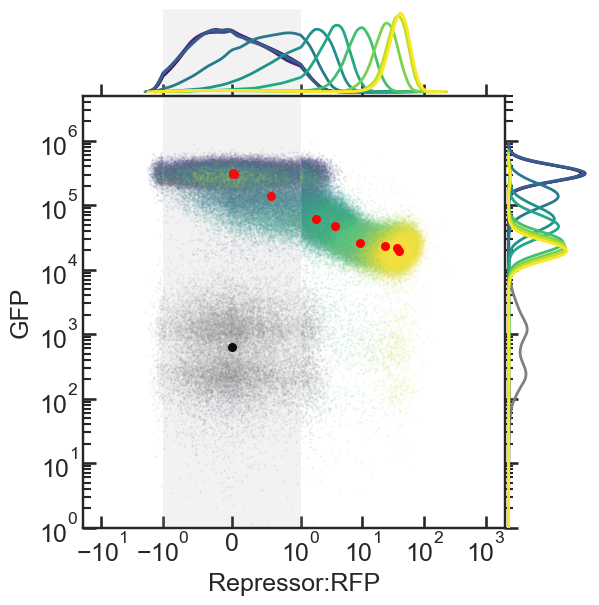

g5, M9, Rep 2


<Figure size 400x400 with 0 Axes>

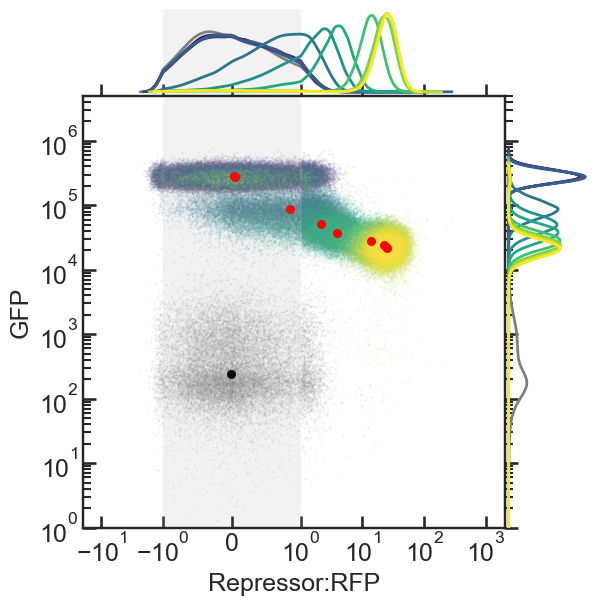

g5, M9, Rep 3


<Figure size 400x400 with 0 Axes>

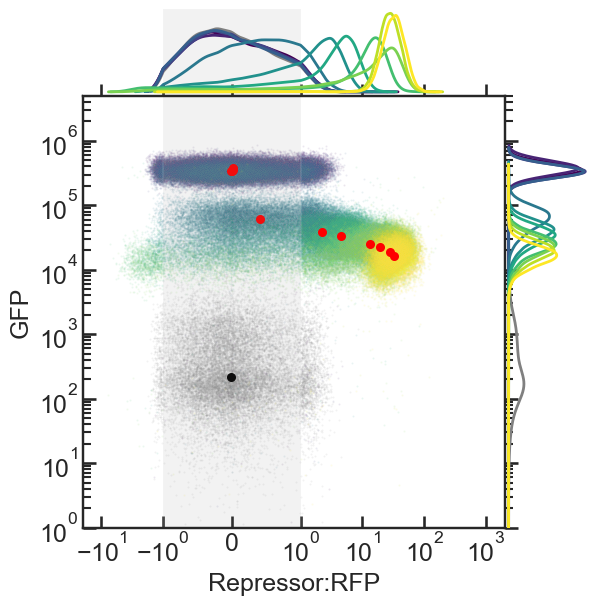

g5, CL, Rep 1


<Figure size 400x400 with 0 Axes>

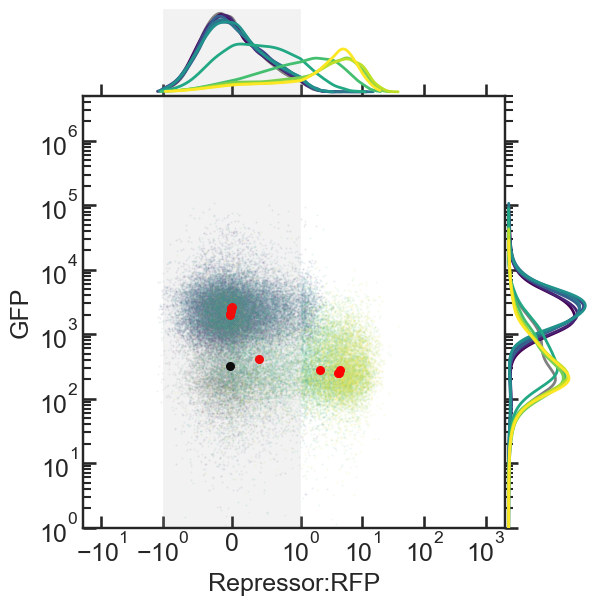

g5, CL, Rep 2


<Figure size 400x400 with 0 Axes>

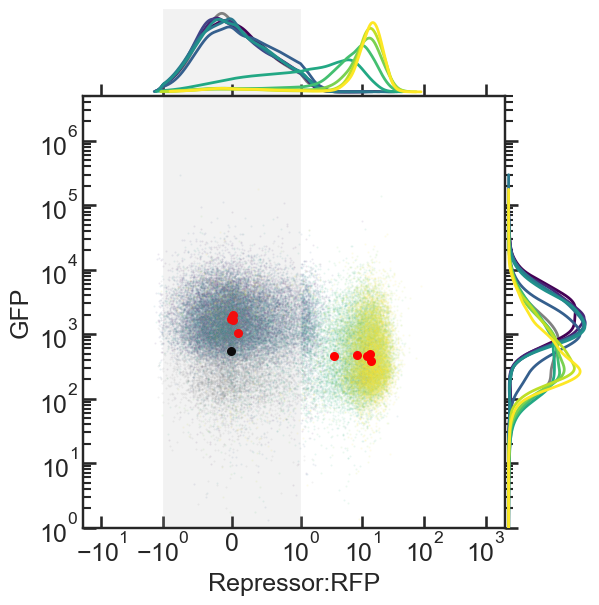

g5, CL, Rep 3


<Figure size 400x400 with 0 Axes>

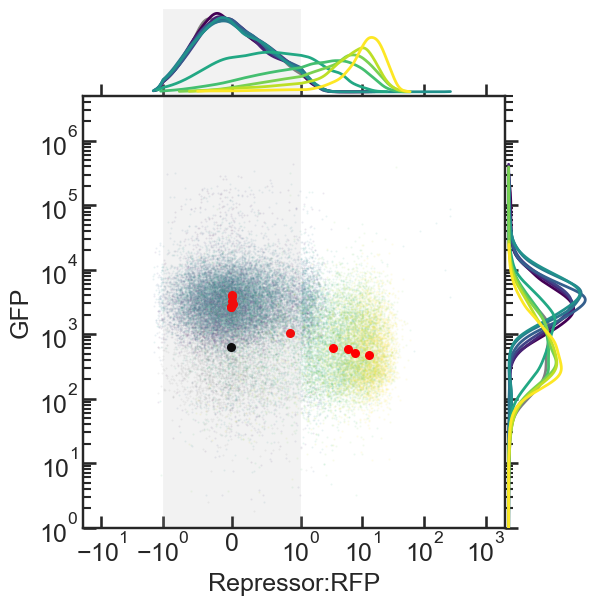

g16, M9, Rep 1


<Figure size 400x400 with 0 Axes>

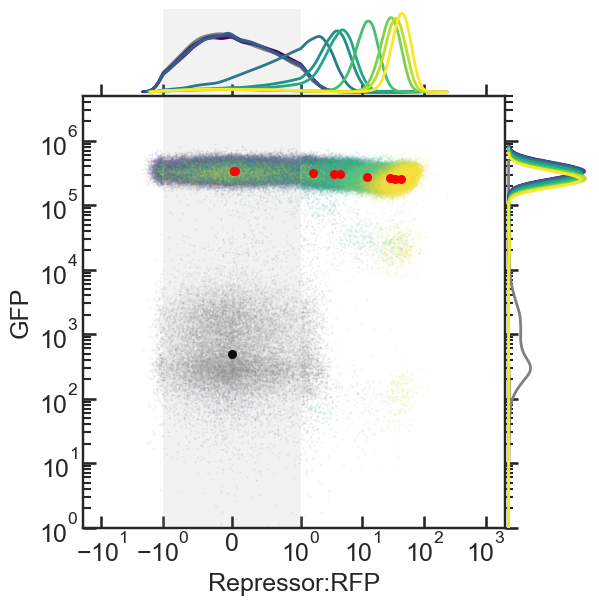

g16, M9, Rep 2


<Figure size 400x400 with 0 Axes>

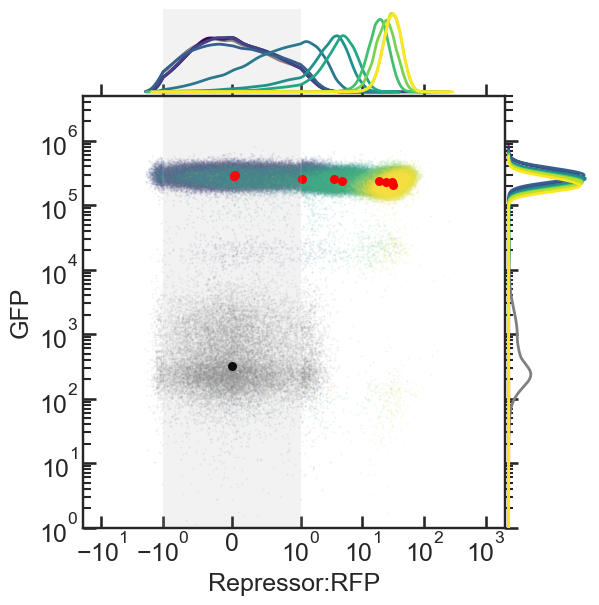

g16, M9, Rep 3


<Figure size 400x400 with 0 Axes>

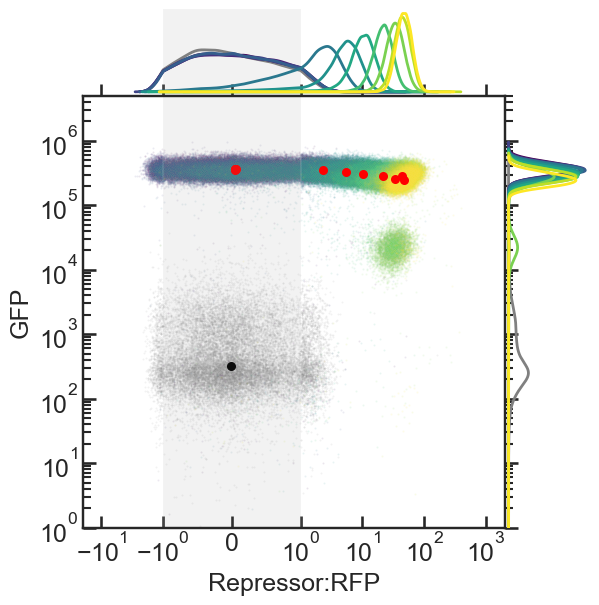

g16, CL, Rep 1


<Figure size 400x400 with 0 Axes>

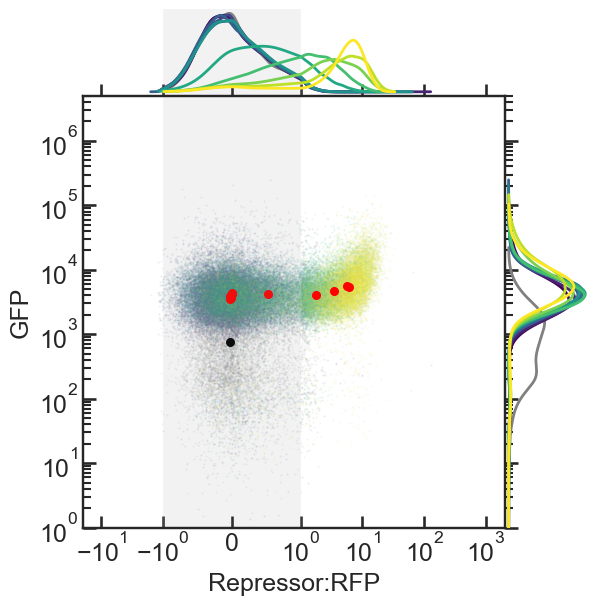

g16, CL, Rep 2


<Figure size 400x400 with 0 Axes>

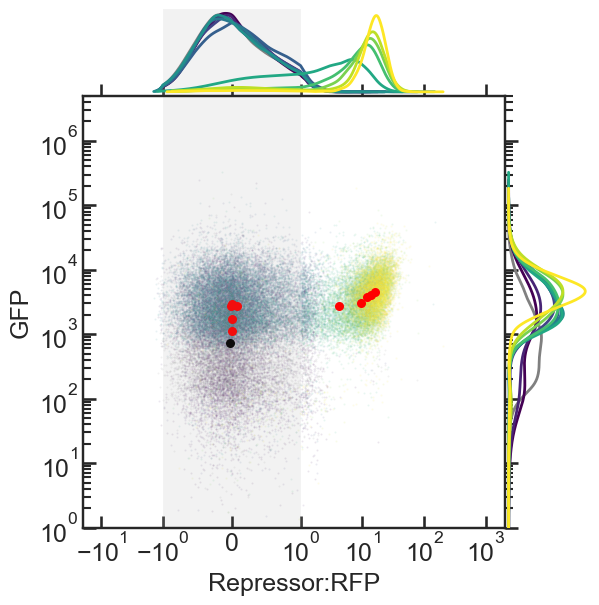

g16, CL, Rep 3


<Figure size 400x400 with 0 Axes>

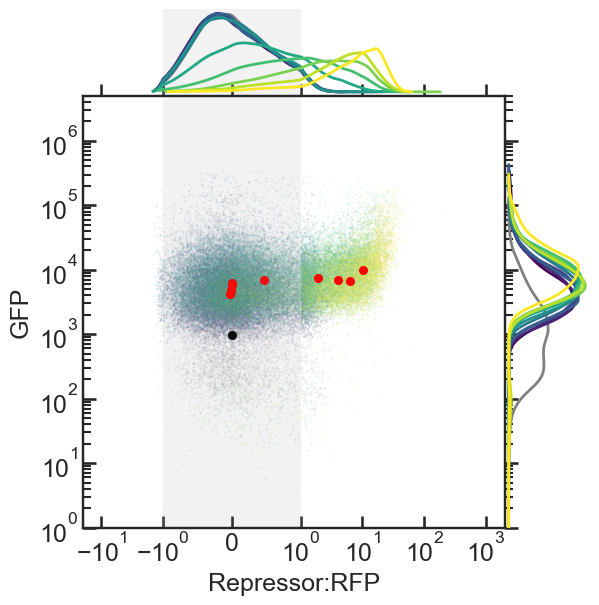

g17, M9, Rep 1


<Figure size 400x400 with 0 Axes>

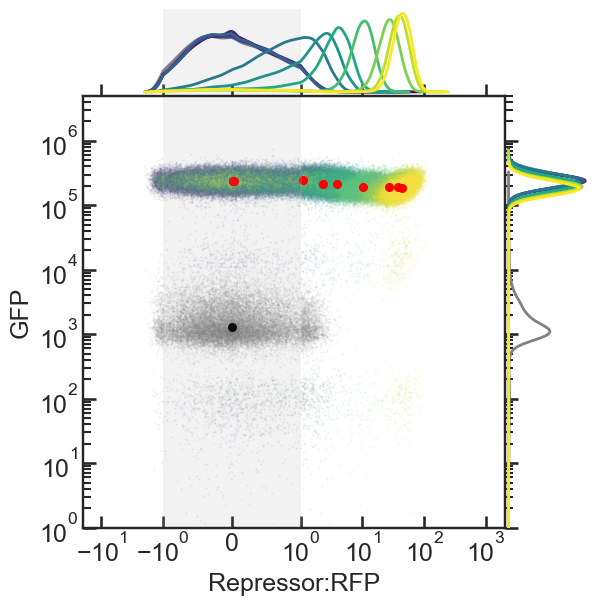

g17, M9, Rep 2


<Figure size 400x400 with 0 Axes>

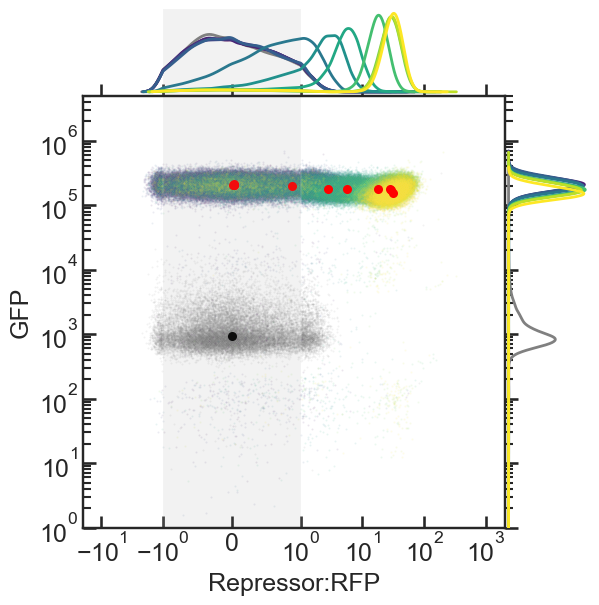

g17, M9, Rep 3


<Figure size 400x400 with 0 Axes>

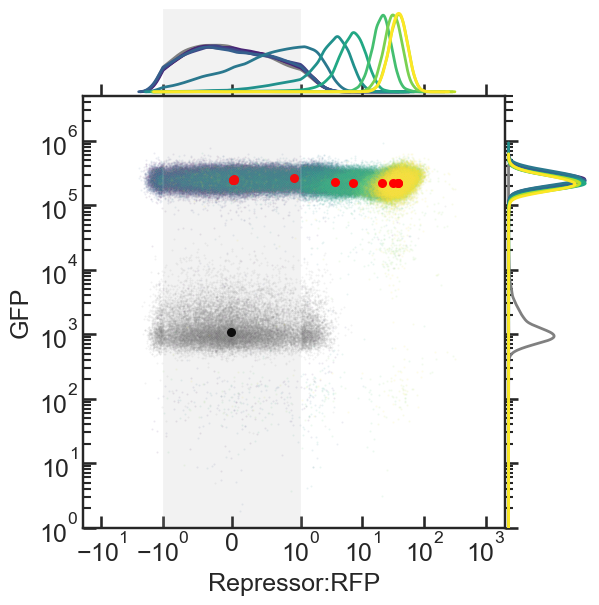

g17, CL, Rep 1


<Figure size 400x400 with 0 Axes>

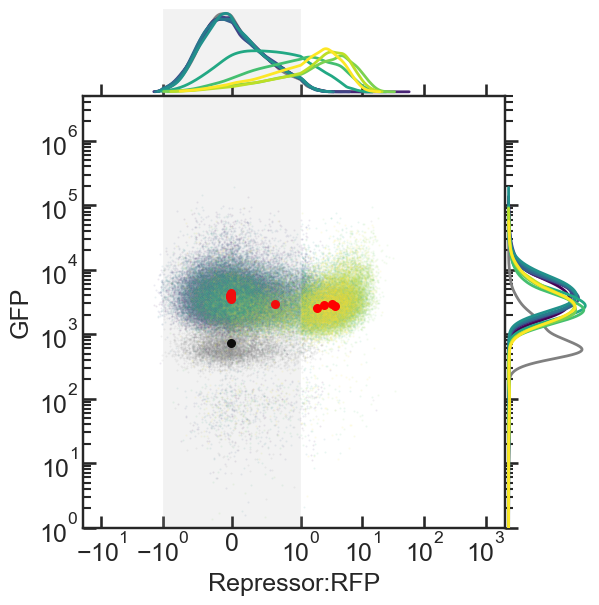

g17, CL, Rep 2


<Figure size 400x400 with 0 Axes>

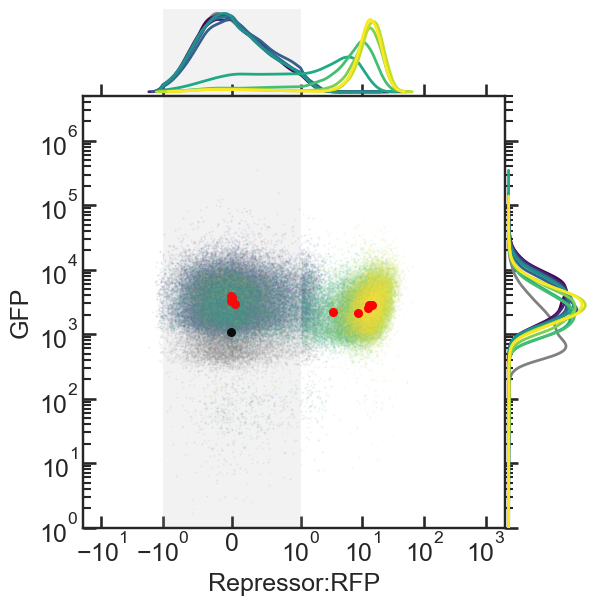

g17, CL, Rep 3


<Figure size 400x400 with 0 Axes>

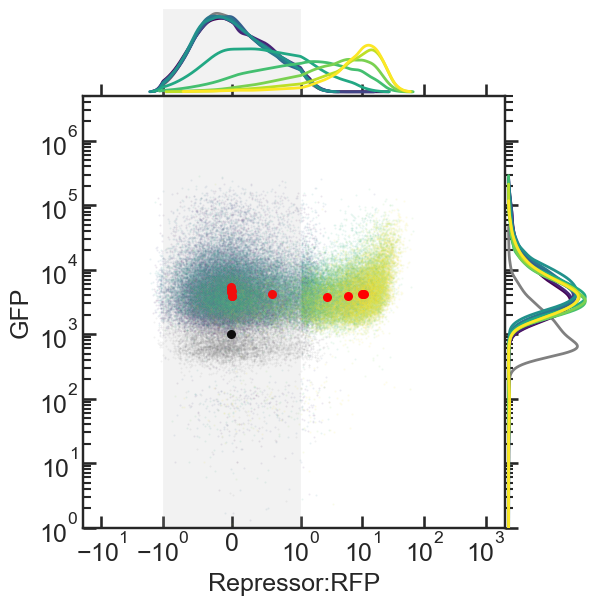

In [9]:
# dCas9:PhlF data
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        for rep in reps:
            atcs = atcs_ls[rep-1][m]

            make_2D_plot(fcs_dict_ls_D, media, grna, rep, atcs, savefig='F')


g1, M9, Rep 1


<Figure size 400x400 with 0 Axes>

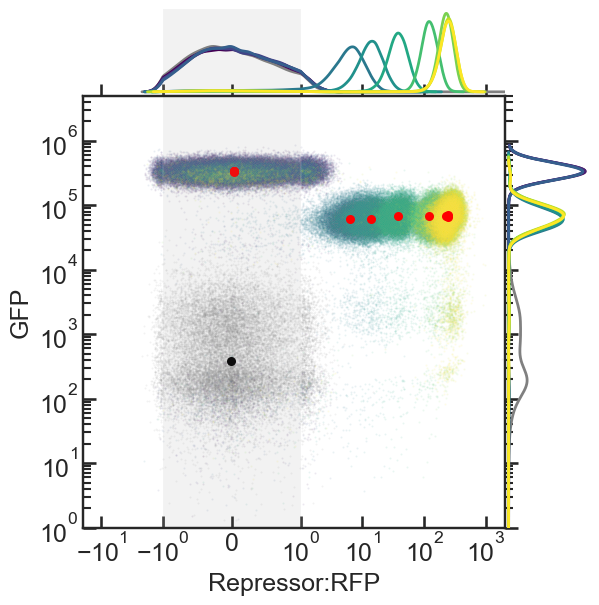

g1, M9, Rep 2


<Figure size 400x400 with 0 Axes>

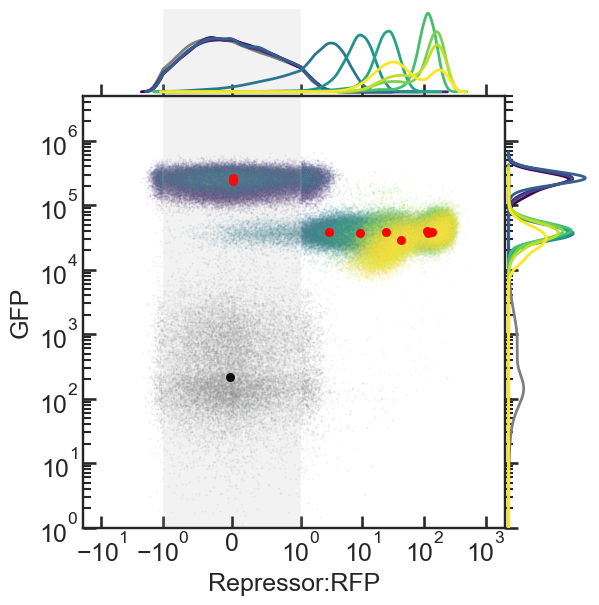

g1, M9, Rep 3


<Figure size 400x400 with 0 Axes>

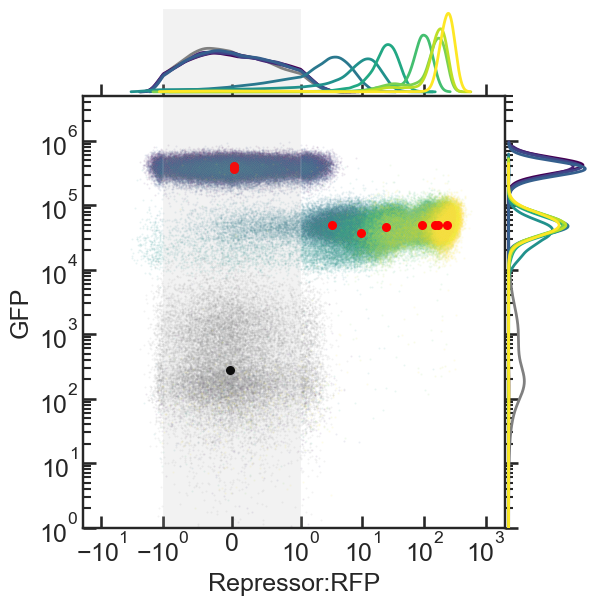

g1, CL, Rep 1


<Figure size 400x400 with 0 Axes>

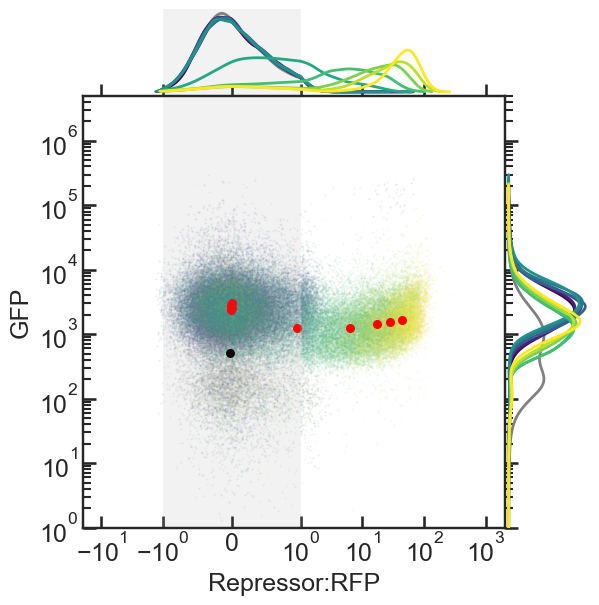

g1, CL, Rep 2


<Figure size 400x400 with 0 Axes>

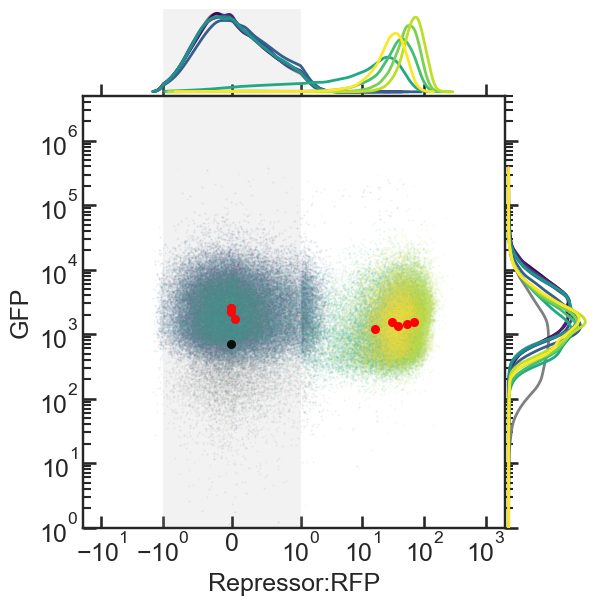

g1, CL, Rep 3


<Figure size 400x400 with 0 Axes>

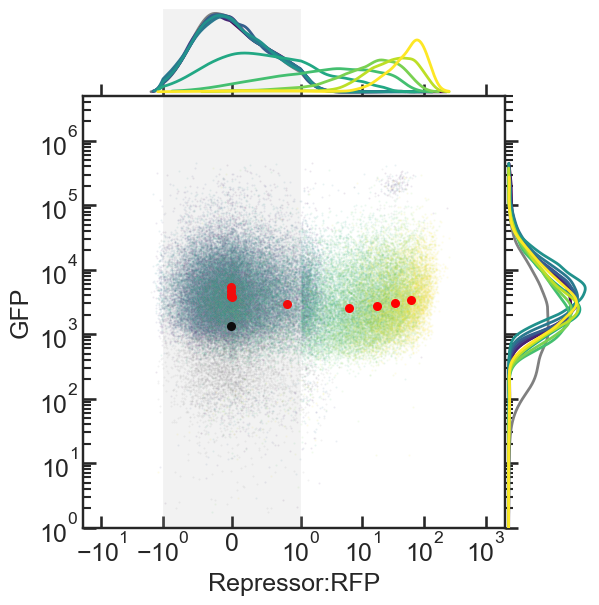

g2, M9, Rep 1


<Figure size 400x400 with 0 Axes>

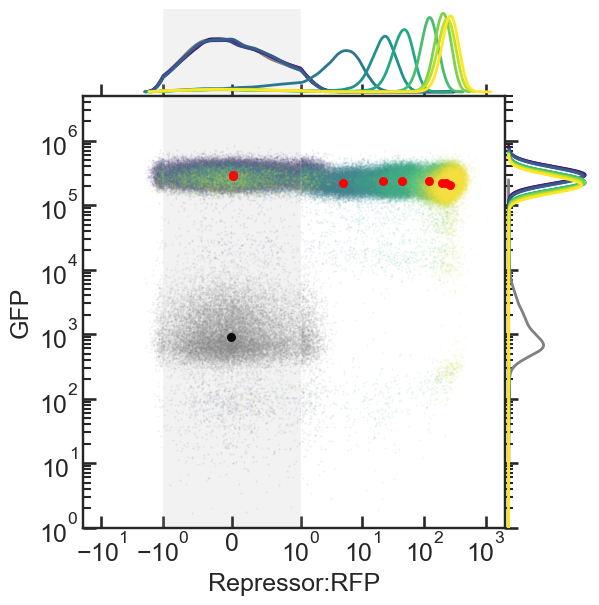

g2, M9, Rep 2


<Figure size 400x400 with 0 Axes>

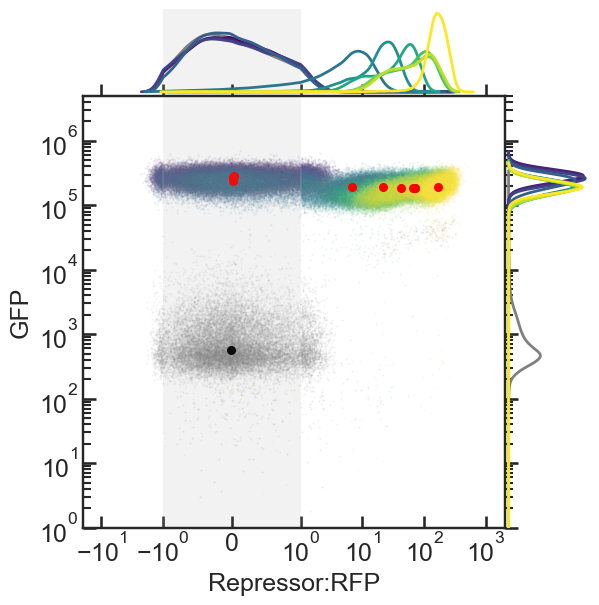

g2, M9, Rep 3


<Figure size 400x400 with 0 Axes>

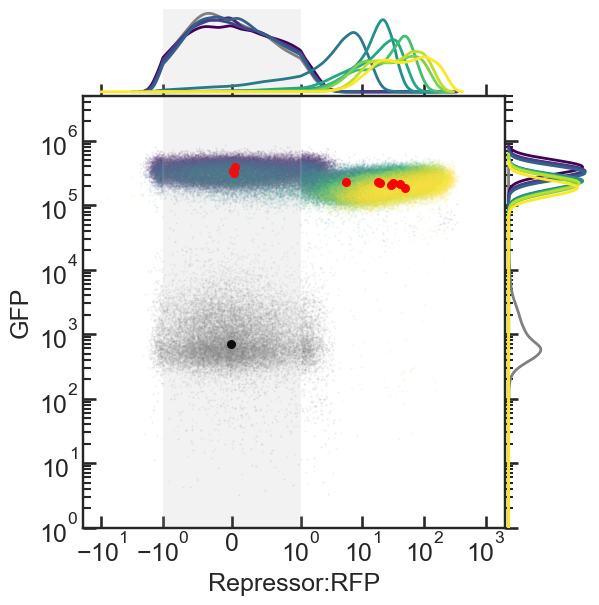

g2, CL, Rep 1


<Figure size 400x400 with 0 Axes>

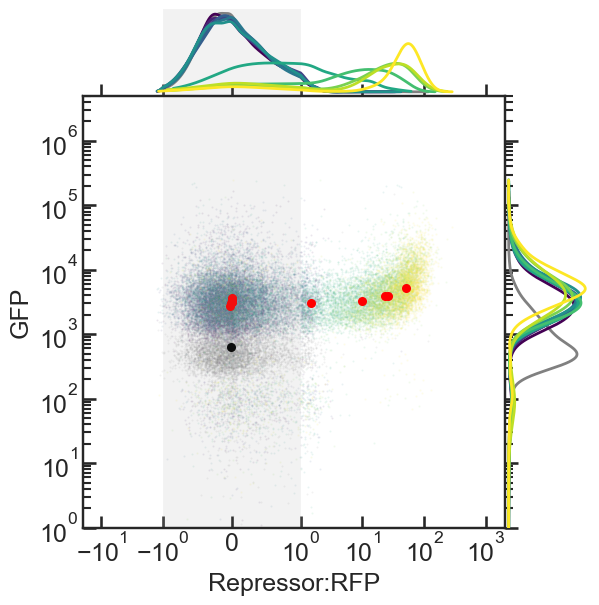

g2, CL, Rep 2


<Figure size 400x400 with 0 Axes>

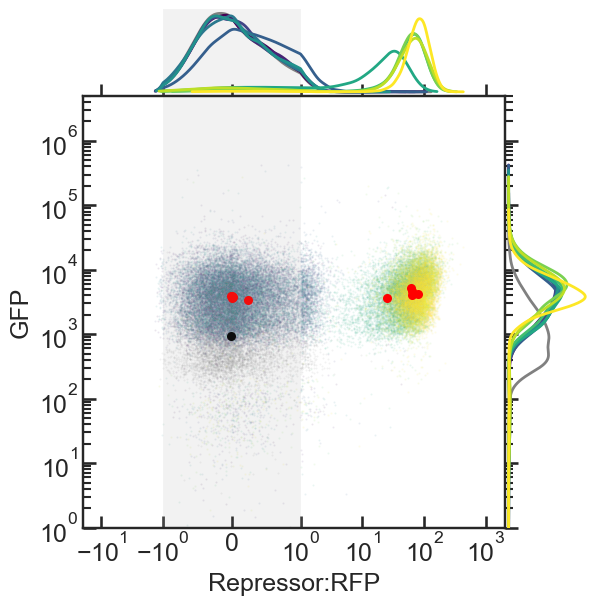

g2, CL, Rep 3


<Figure size 400x400 with 0 Axes>

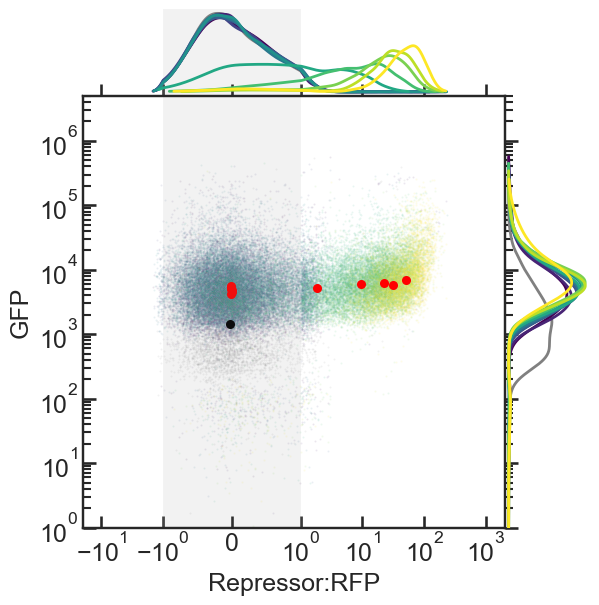

g3, M9, Rep 1


<Figure size 400x400 with 0 Axes>

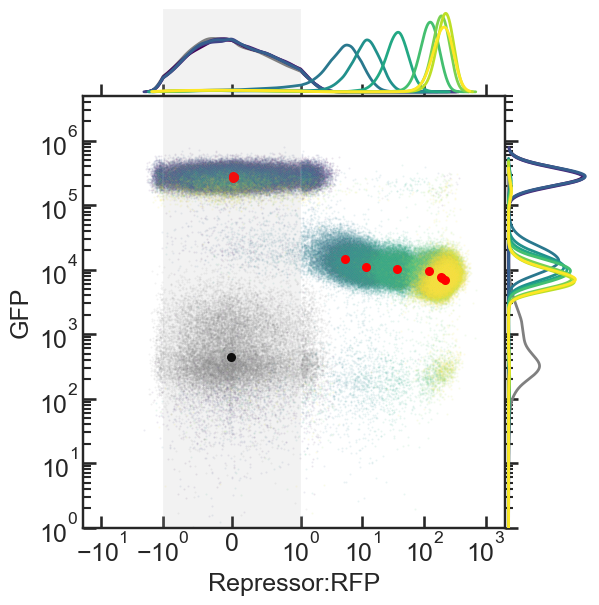

g3, M9, Rep 2


<Figure size 400x400 with 0 Axes>

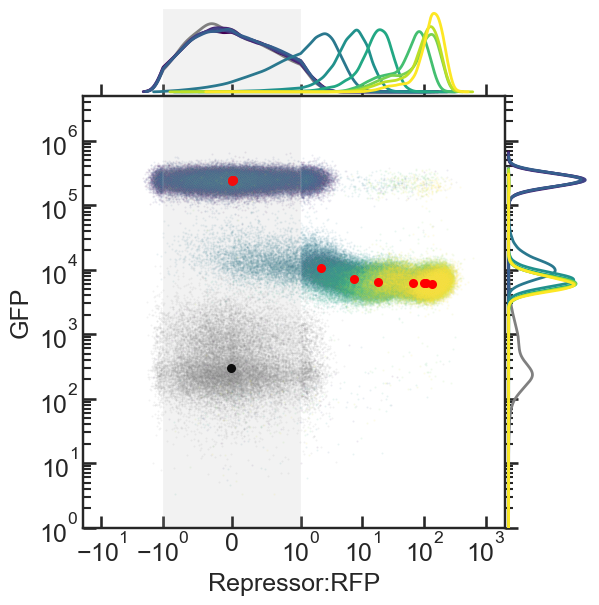

g3, M9, Rep 3


<Figure size 400x400 with 0 Axes>

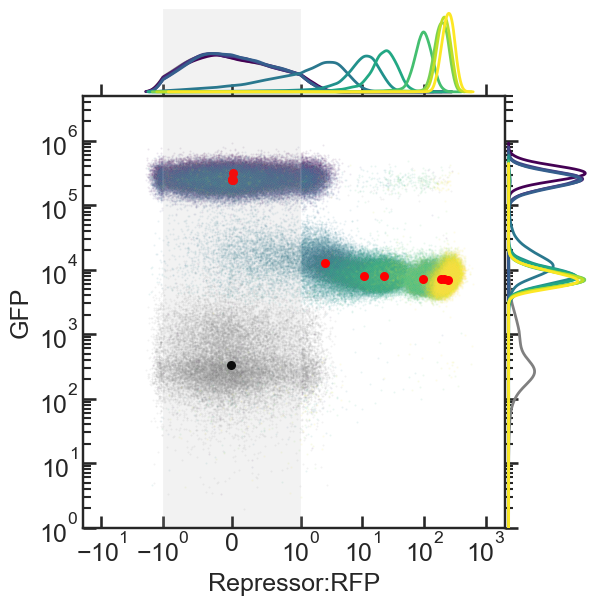

g3, CL, Rep 1


<Figure size 400x400 with 0 Axes>

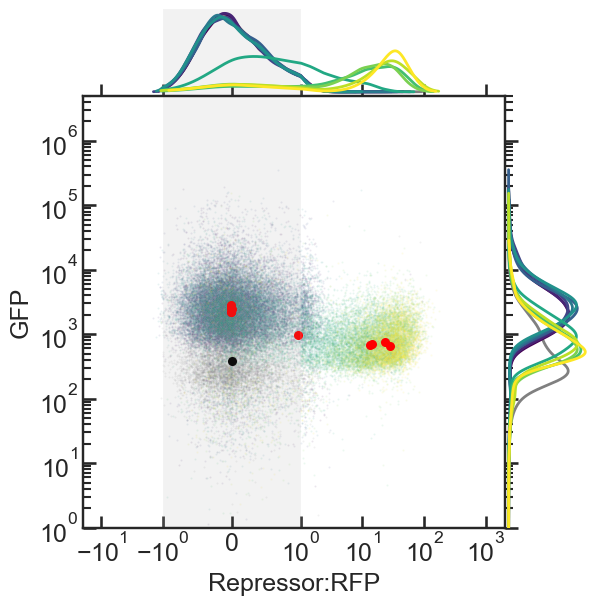

g3, CL, Rep 2


<Figure size 400x400 with 0 Axes>

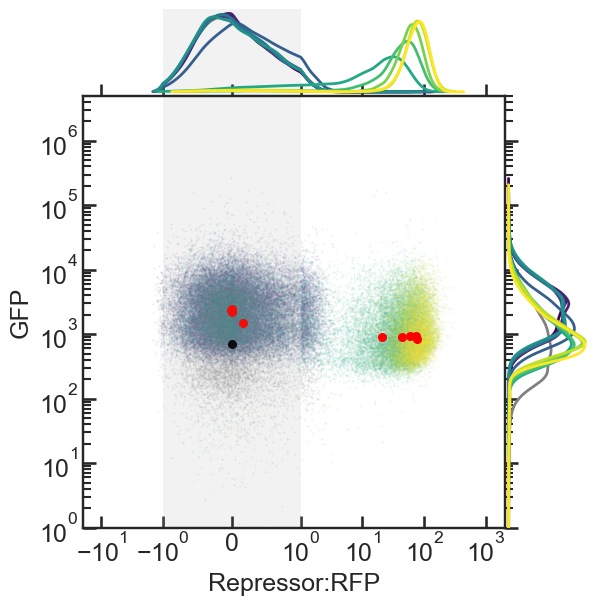

g3, CL, Rep 3


<Figure size 400x400 with 0 Axes>

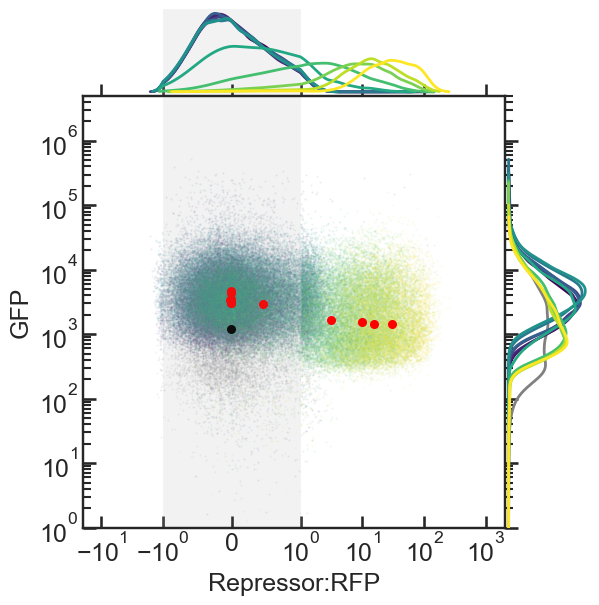

g5, M9, Rep 1


<Figure size 400x400 with 0 Axes>

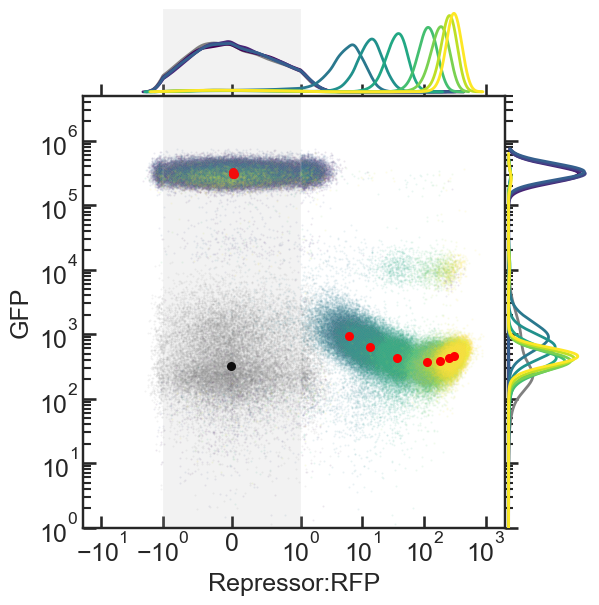

g5, M9, Rep 2


<Figure size 400x400 with 0 Axes>

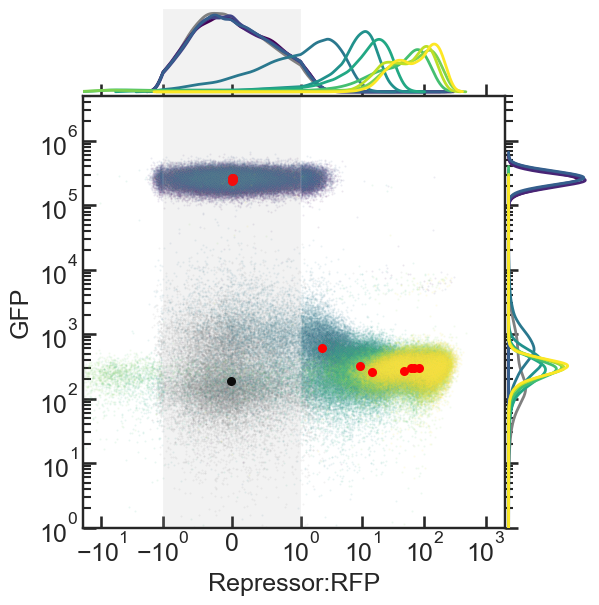

g5, M9, Rep 3


<Figure size 400x400 with 0 Axes>

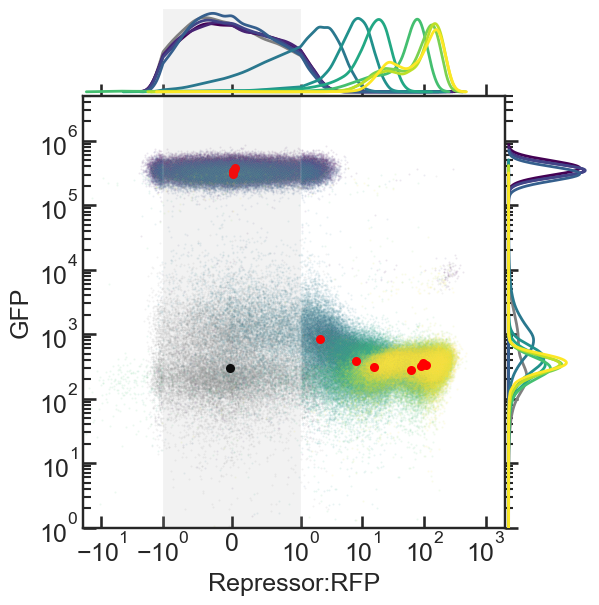

g5, CL, Rep 1


<Figure size 400x400 with 0 Axes>

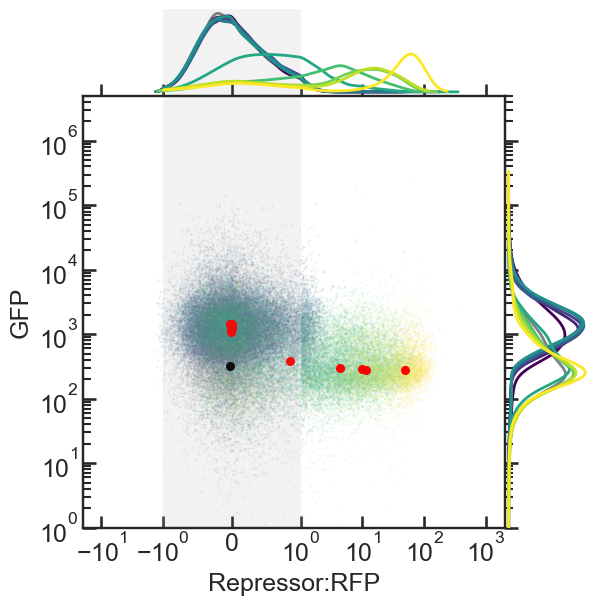

g5, CL, Rep 2


<Figure size 400x400 with 0 Axes>

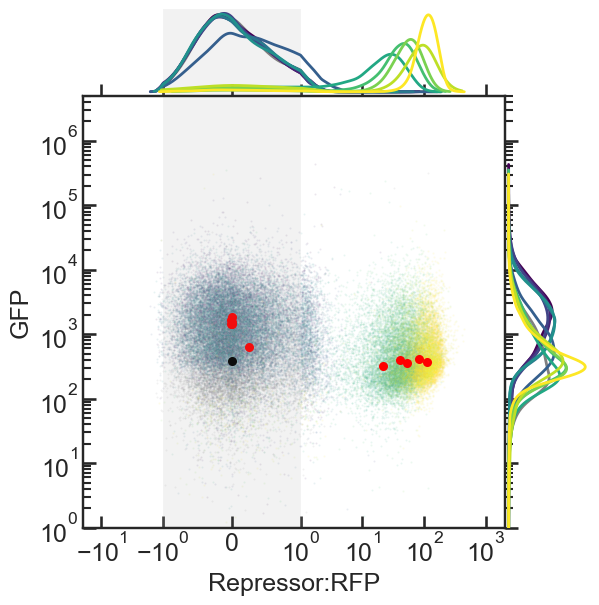

g5, CL, Rep 3


<Figure size 400x400 with 0 Axes>

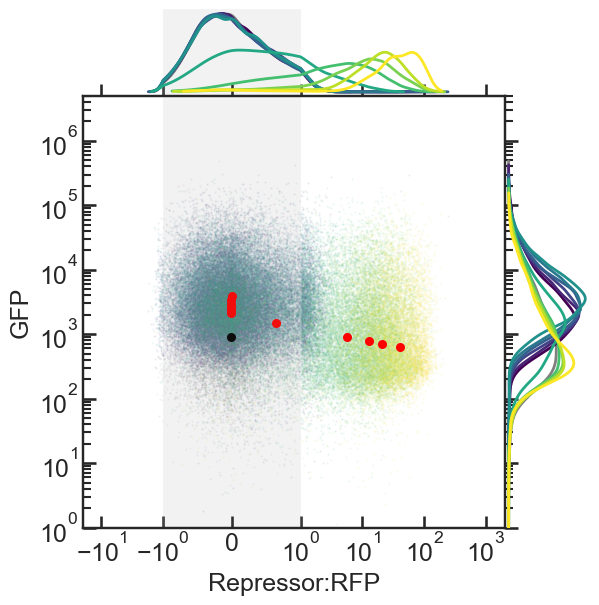

g16, M9, Rep 1


<Figure size 400x400 with 0 Axes>

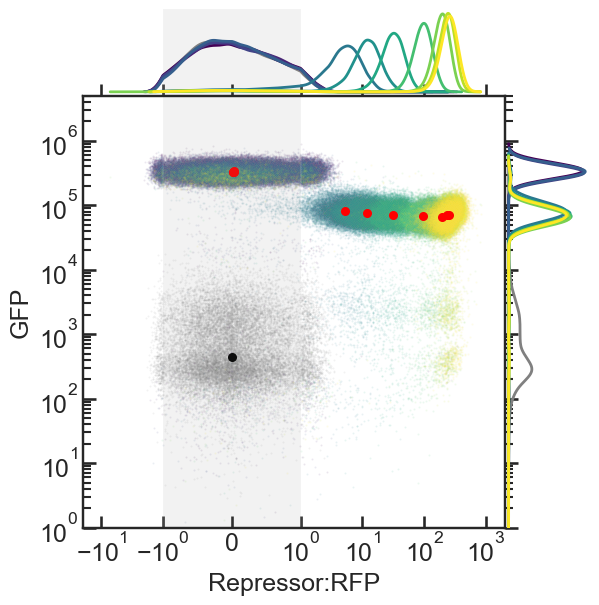

g16, M9, Rep 2


<Figure size 400x400 with 0 Axes>

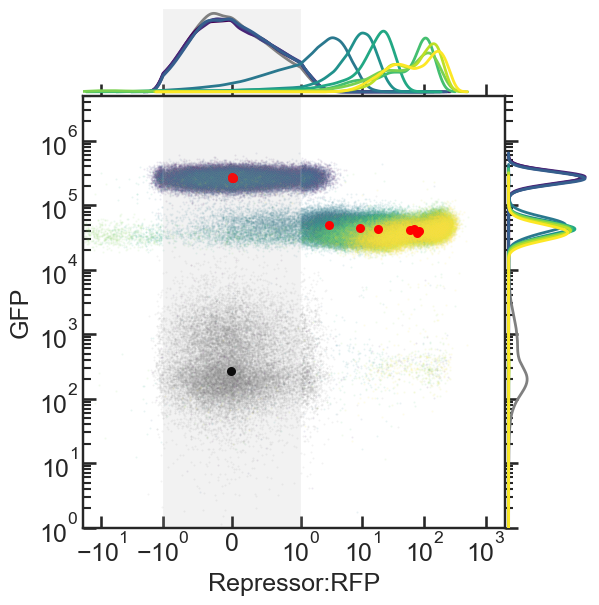

g16, M9, Rep 3


<Figure size 400x400 with 0 Axes>

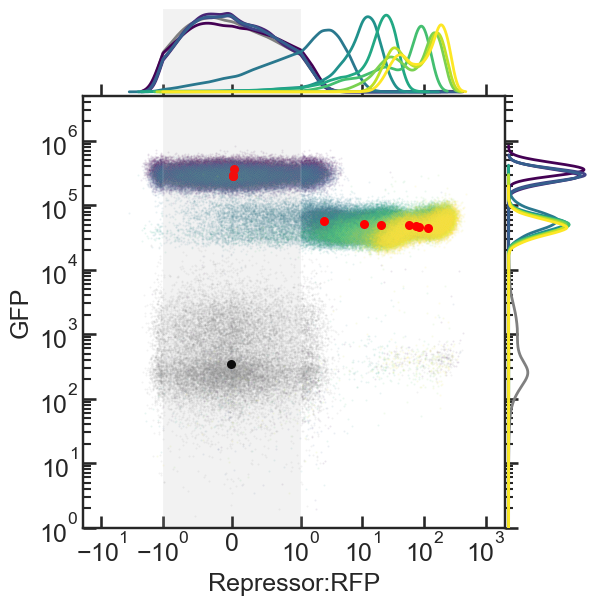

g16, CL, Rep 1


<Figure size 400x400 with 0 Axes>

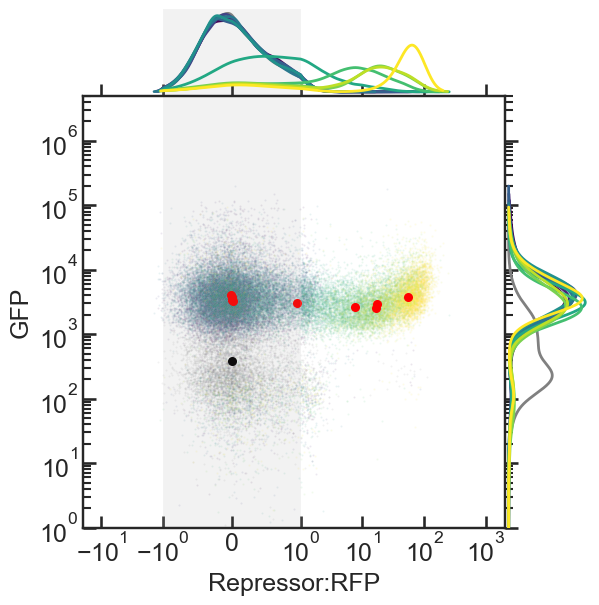

g16, CL, Rep 2


<Figure size 400x400 with 0 Axes>

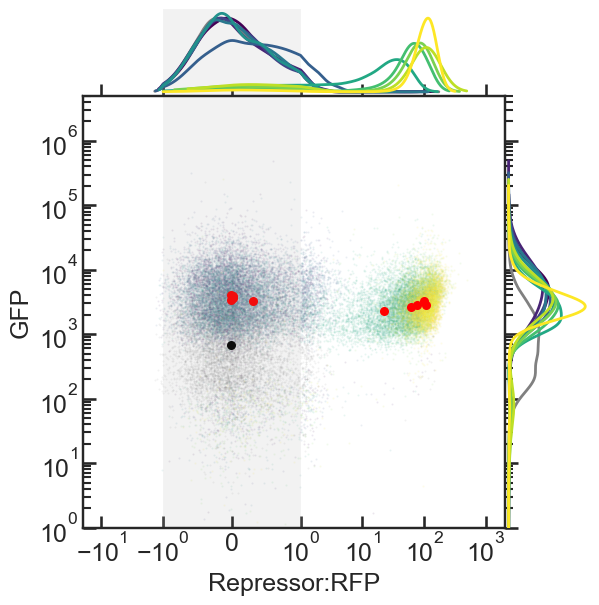

g16, CL, Rep 3


<Figure size 400x400 with 0 Axes>

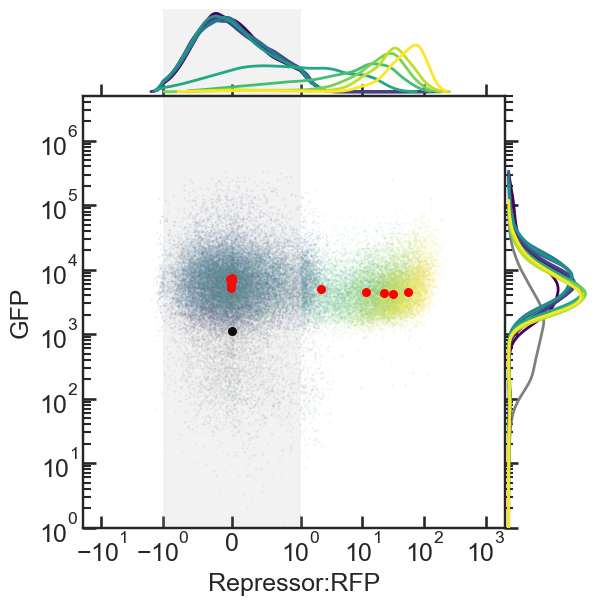

g17, M9, Rep 1


<Figure size 400x400 with 0 Axes>

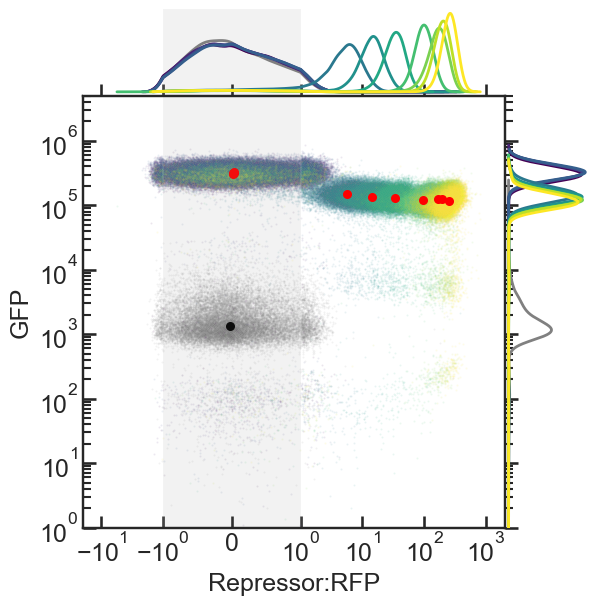

g17, M9, Rep 2


<Figure size 400x400 with 0 Axes>

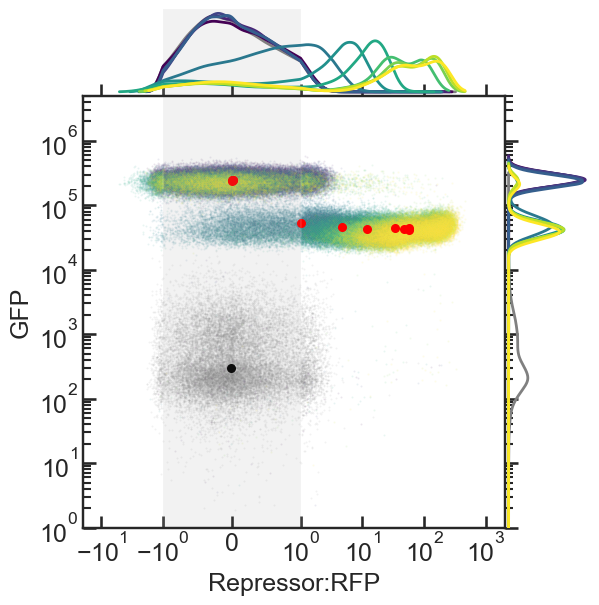

g17, M9, Rep 3


<Figure size 400x400 with 0 Axes>

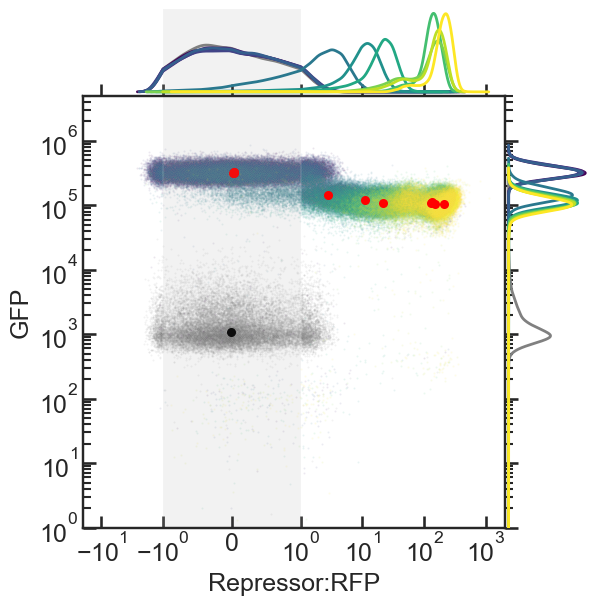

g17, CL, Rep 1


<Figure size 400x400 with 0 Axes>

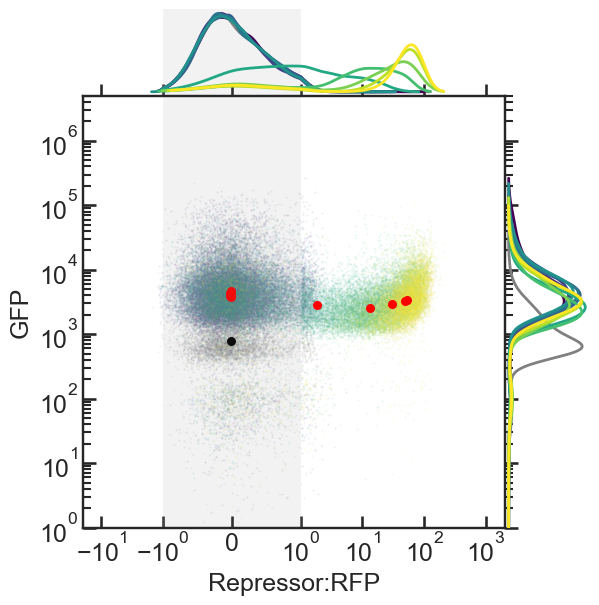

g17, CL, Rep 2


<Figure size 400x400 with 0 Axes>

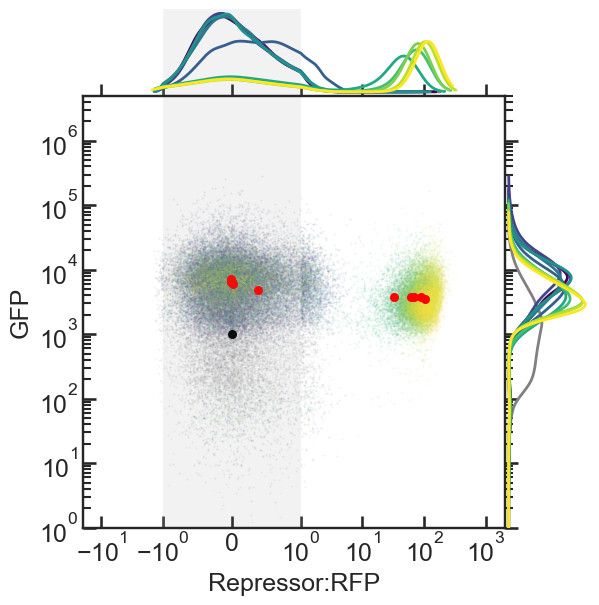

g17, CL, Rep 3


<Figure size 400x400 with 0 Axes>

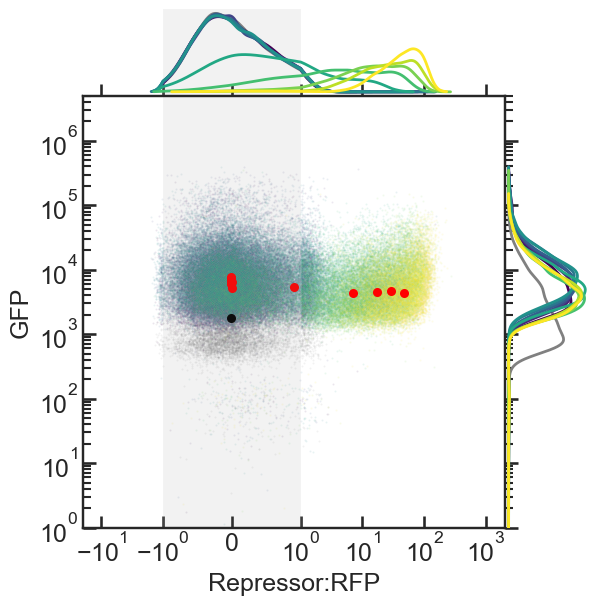

In [10]:
# PhlF data
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        for rep in reps:
            atcs = atcs_ls[rep-1][m]

            make_2D_plot(fcs_dict_ls_P, media, grna, rep, atcs, savefig='P')


## Plots of MCMC results

Supplemental Figs 14-24.

Requires prior pickling of MCMC runs.

In [11]:
# generate a dataframe of just median (RFP,GFP) values, grouping replicates

df_ls_D = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls_D[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])

                # #bandaid fix: set negative values to epsilon
                # med_gfp = np.max([np.median(gfps), 1e-6])
                # med_rfp = np.max([np.median(rfps), 1e-6])
                med_gfp = np.median(gfps)
                med_rfp = np.median(rfps)
                
                row_to_append = [grna, media, np.log(med_gfp), med_rfp] #<- ln() the GFP values
                df_ls_D.append(row_to_append)

df_medians_D = pd.DataFrame(df_ls_D, columns=['gRNA','Media','ln median GFP', 'median RFP'])



df_ls_P = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls_P[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])

                # #bandaid fix: set negative values to epsilon
                # med_gfp = np.max([np.median(gfps), 1e-6])
                # med_rfp = np.max([np.median(rfps), 1e-6])
                med_gfp = np.median(gfps)
                med_rfp = np.median(rfps)
                
                row_to_append = [grna, media, np.log(med_gfp), med_rfp] #<- ln() the GFP values
                df_ls_P.append(row_to_append)

df_medians_P = pd.DataFrame(df_ls_P, columns=['gRNA','Media','ln median GFP', 'median RFP'])

dCas9:PhlF data
g1


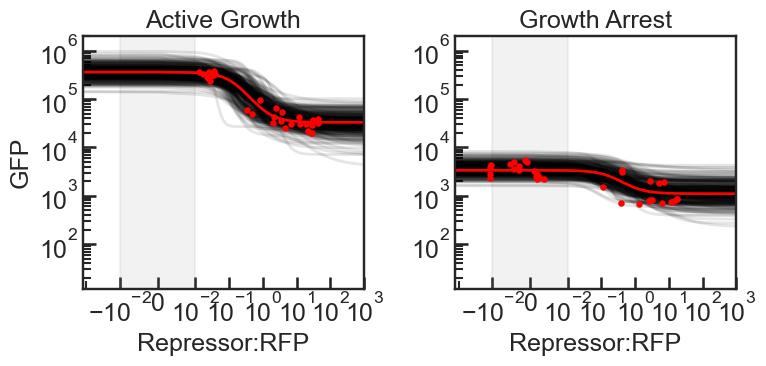

g2


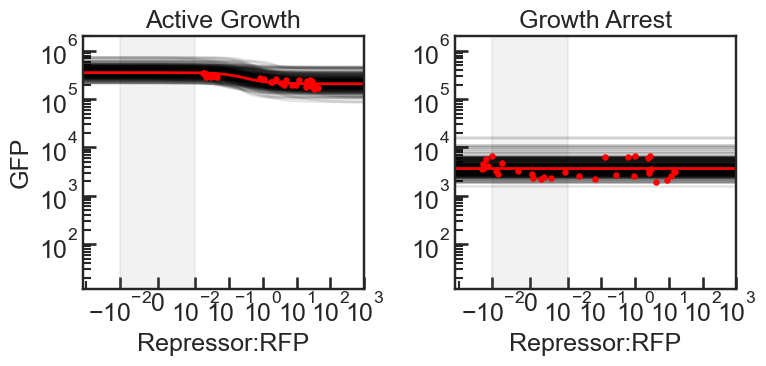

g3


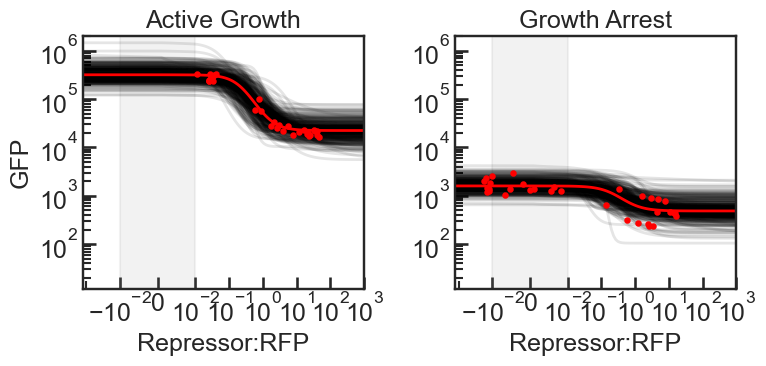

g5


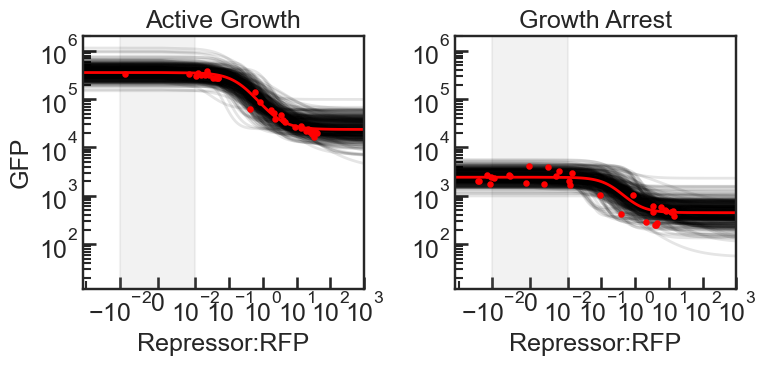

g16


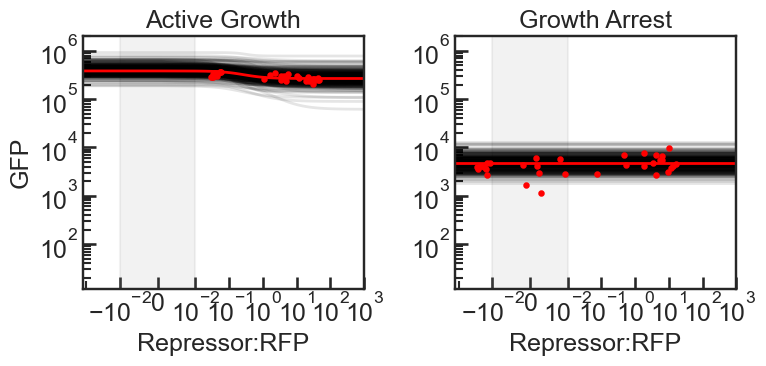

g17


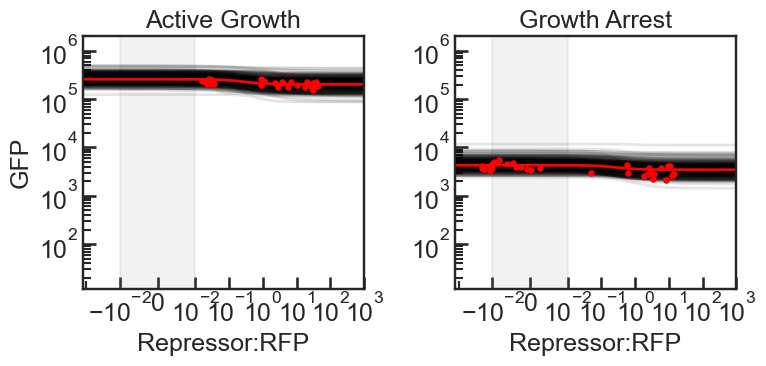

In [12]:
print('dCas9:PhlF data')


trajectories_to_plot = 300

for grna in grnas:
    print(grna)
    fig, ax = plt.subplots(1,2, figsize=(8,4), sharey=False, sharex=True)
    for m in range(len(medias)):
        media = medias[m]

        dfslice = df_medians_D[(df_medians_D['gRNA'] == grna) &
                             (df_medians_D['Media'] == media)]
        
        filename = './MCMC_outputs/D_'+grna+'_'+media+'_32_10000.pkl'

        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()

        flat_samples = sampler.get_chain(discard=9000, flat=True)

        inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
        
        betas = np.empty(trajectories_to_plot)
        alphas = np.empty(trajectories_to_plot)
        Ks = np.empty(trajectories_to_plot)
        ns = np.empty(trajectories_to_plot)
        for i in range(len(inds)):
            ind = inds[i]
            sample = flat_samples[ind]
            xsmooth = np.logspace(-3,3,100)
            ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
            # append a negative point on the far left for plotting
            xsmooth = np.insert(xsmooth, 0, -10)
            ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
            
            ax[m].plot(xsmooth, np.exp(ysmooth), c='k', alpha=0.1)

            betas[i] = sample[0]
            alphas[i] = sample[1]
            Ks[i] = sample[2]
            ns[i] = sample[3]

        # Plot curve with medians of all parameter values
        xsmooth = np.logspace(-3,3,100)
        med_sample = [np.median(betas),
                       np.median(alphas),
                       np.median(Ks),
                       np.median(ns)]
        ysmooth = np.log(Hill_rep_fun(xsmooth,med_sample))
        xsmooth = np.insert(xsmooth, 0, -10)
        ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, med_sample)))
        ax[m].plot(xsmooth, np.exp(ysmooth), c='r')

        rfp_scatters = dfslice['median RFP'].values
        gfp_scatters = dfslice['ln median GFP'].values
        ax[m].scatter(rfp_scatters, np.exp(gfp_scatters), color='r', s=10, zorder=100)
        
        # sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
        #                 color='r', ax=ax[m], zorder=100)
        
        ax[m].set_xscale('symlog', linthresh=.01)
        ax[m].set_yscale('log')
        # ax[m].set_xscale('log')
        # ax[m].set_title(media)
        ax[m].axvspan(-.01,.01, color='grey', alpha=0.1)
        ax[m].set_xlim((-.13,1e3))
        xticks = ax[m].get_xticks()
        xticklabels = ax[m].get_xticklabels()
        ax[m].set_xticks(xticks[2:])
        ax[m].set_xticklabels(xticklabels[2:])

    yminmin = 1.2e1
    ymaxmax = 2e6
    ax[0].set_ylim((yminmin, ymaxmax))
    ax[1].set_ylim((yminmin, ymaxmax))

    ax[0].set_title('Active Growth')
    ax[1].set_title('Growth Arrest')
    ax[0].set_ylabel('GFP')
    ax[0].set_xlabel('Repressor:RFP')
    ax[1].set_xlabel('Repressor:RFP')
    # plt.suptitle(grna)
    plt.tight_layout()
    plt.savefig('./figs/BPEplots/F_'+grna+'.pdf')
    plt.show()
        

PhlF data
g1


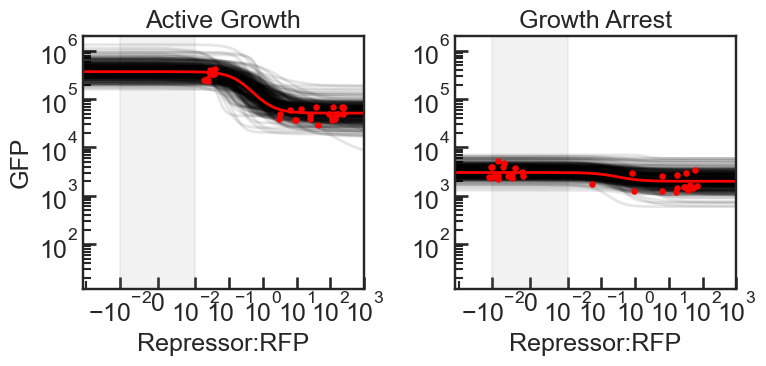

g2


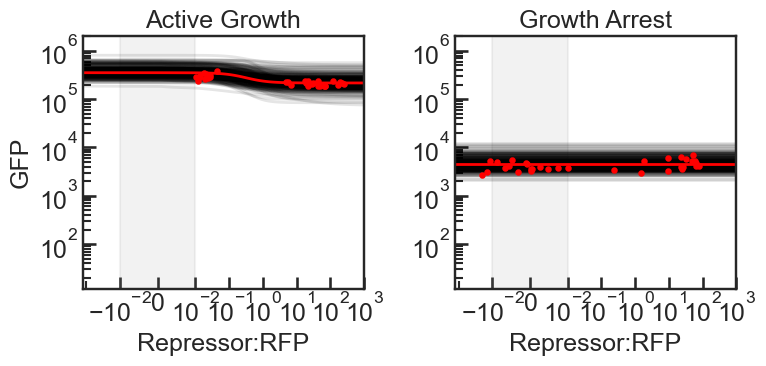

g3


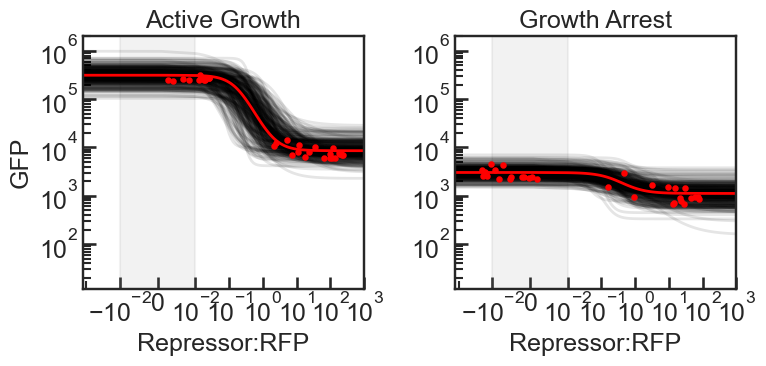

g5


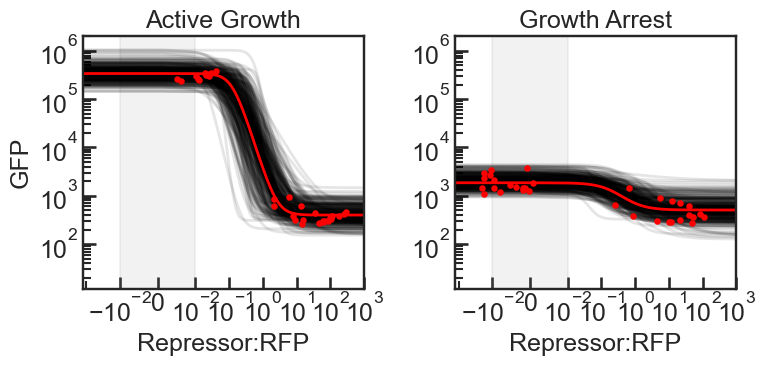

g16


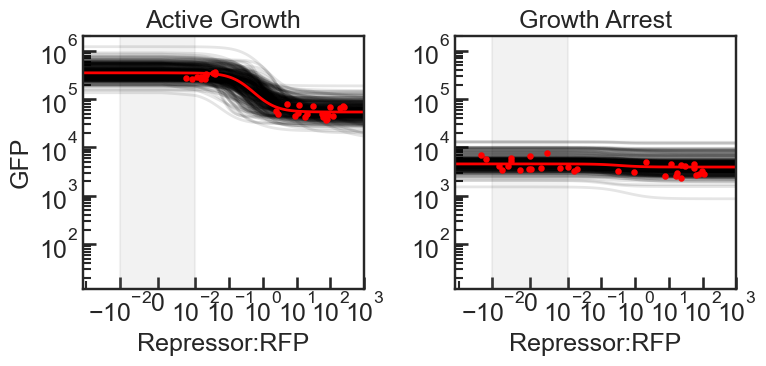

g17


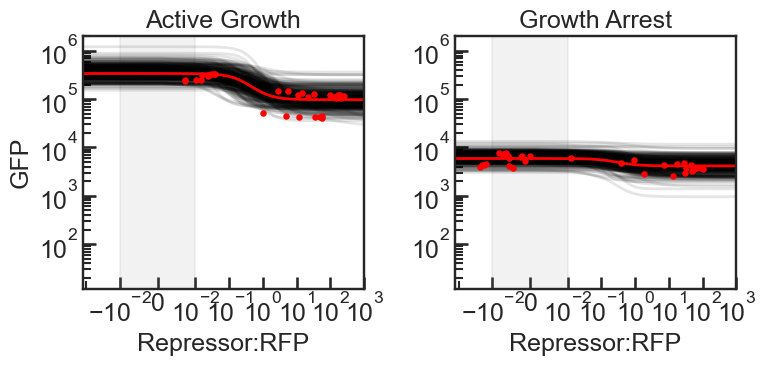

In [13]:
print('PhlF data')


trajectories_to_plot = 300

for grna in grnas:
    print(grna)
    fig, ax = plt.subplots(1,2, figsize=(8,4), sharey=False, sharex=True)
    for m in range(len(medias)):
        media = medias[m]

        dfslice = df_medians_P[(df_medians_P['gRNA'] == grna) &
                             (df_medians_P['Media'] == media)]
        
        filename = './MCMC_outputs/P_'+grna+'_'+media+'_32_10000.pkl'

        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()

        flat_samples = sampler.get_chain(discard=9000, flat=True)

        inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
        
        betas = np.empty(trajectories_to_plot)
        alphas = np.empty(trajectories_to_plot)
        Ks = np.empty(trajectories_to_plot)
        ns = np.empty(trajectories_to_plot)
        for i in range(len(inds)):
            ind = inds[i]
            sample = flat_samples[ind]
            xsmooth = np.logspace(-3,3,100)
            ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
            # append a negative point on the far left for plotting
            xsmooth = np.insert(xsmooth, 0, -10)
            ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
            
            ax[m].plot(xsmooth, np.exp(ysmooth), c='k', alpha=0.1)

            betas[i] = sample[0]
            alphas[i] = sample[1]
            Ks[i] = sample[2]
            ns[i] = sample[3]

        # Plot curve with medians of all parameter values
        xsmooth = np.logspace(-3,3,100)
        med_sample = [np.median(betas),
                       np.median(alphas),
                       np.median(Ks),
                       np.median(ns)]
        ysmooth = np.log(Hill_rep_fun(xsmooth,med_sample))
        xsmooth = np.insert(xsmooth, 0, -10)
        ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, med_sample)))
        ax[m].plot(xsmooth, np.exp(ysmooth), c='r')
        
        rfp_scatters = dfslice['median RFP'].values
        gfp_scatters = dfslice['ln median GFP'].values
        ax[m].scatter(rfp_scatters, np.exp(gfp_scatters), color='r', s=10, zorder=100)
        
        # sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
        #                 color='r', ax=ax[m], zorder=100)
        
        ax[m].set_xscale('symlog', linthresh=.01)
        ax[m].set_yscale('log')
        # ax[m].set_xscale('log')
        # ax[m].set_title(media)
        ax[m].axvspan(-.01,.01, color='grey', alpha=0.1)
        ax[m].set_xlim((-.13,1e3))
        xticks = ax[m].get_xticks()
        xticklabels = ax[m].get_xticklabels()
        ax[m].set_xticks(xticks[2:])
        ax[m].set_xticklabels(xticklabels[2:])

    # ymin1, ymax1 = ax[0].get_ylim()
    # ymin2, ymax2 = ax[1].get_ylim()
    # yminmin = np.min([ymin1, ymin2])
    # ymaxmax = np.max([ymax1, ymax2])

    yminmin = 1.2e1
    ymaxmax = 2e6
    ax[0].set_ylim((yminmin, ymaxmax))
    ax[1].set_ylim((yminmin, ymaxmax))

    ax[0].set_title('Active Growth')
    ax[1].set_title('Growth Arrest')
    ax[0].set_ylabel('GFP')
    ax[0].set_xlabel('Repressor:RFP')
    ax[1].set_xlabel('Repressor:RFP')
    # plt.suptitle(grna)
    plt.tight_layout()
    plt.savefig('./figs/BPEplots/P_'+grna+'.pdf')
    plt.show()
        

## Analysis of noise

### Plot KDEs

Fig. 5d

In [14]:
# make a KDE of GFP values for each experimental condition

kdes_dict_D = dict()
kdes_dict_P = dict()

for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            fcs_gated_dict_D = fcs_dict_ls_D[rep-1]
            fcs_gated_dict_P = fcs_dict_ls_P[rep-1]
            atcs = atcs_ls[rep-1][m]
            plot_inds = plot_inds_ls[rep-1][m]
            for a in range(1,len(atcs)): # ignore Blank values
                atc = atcs[a]

                fcs_D = fcs_gated_dict_D[media+'_'+grna+'_'+atc]
                fcs_P = fcs_gated_dict_P[media+'_'+grna+'_'+atc]

                # get KDE for DP data
                loggfps = np.log10(np.array(fcs_D[:,5]))
                loggfps = loggfps[~np.isnan(loggfps)] # remove nan values
                loggfps = loggfps[~np.isinf(loggfps)] # remove inf values

                # rescale values by median
                loggfps /= np.median(loggfps)
                
                # do a KDE of the gfp values
                kde = stats.gaussian_kde(loggfps)

                kdes_dict_D[media+'_'+grna+'_'+atc] = kde

                # get KDE for P data
                loggfps = np.log10(np.array(fcs_P[:,5]))
                loggfps = loggfps[~np.isnan(loggfps)] # remove nan values
                loggfps = loggfps[~np.isinf(loggfps)] # remove inf values

                # rescale values by median
                loggfps /= np.median(loggfps)
                
                # do a KDE of the gfp values
                kde = stats.gaussian_kde(loggfps)

                kdes_dict_P[media+'_'+grna+'_'+atc] = kde
                


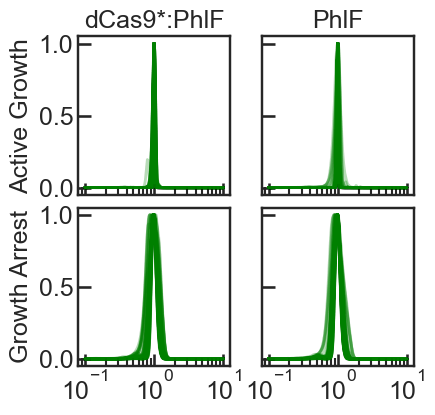

In [25]:
# Plot KDE of GFP values for each condition

xrange = np.logspace(-1,1,300)

fig, ax = plt.subplots(2,2, figsize=(4,4), sharey='row', sharex=True)

width_ls_M9_D = []
width_ls_CL_D = []
width_ls_M9_P = []
width_ls_CL_P = []

for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            atcs = atcs_ls[rep-1][m]            
            for a in range(1,len(atcs)):
                atc = atcs[a]
                kde_D = kdes_dict_D[media+'_'+grna+'_'+atc]
                kde_P = kdes_dict_P[media+'_'+grna+'_'+atc]
                yvals_D = kde_D(xrange)
                yvals_P = kde_P(xrange)
                yvals_D /= np.max(yvals_D)
                yvals_P /= np.max(yvals_P)

                ax[m,0].plot(xrange, yvals_D, alpha=0.1, c='g')
                ax[m,1].plot(xrange, yvals_P, alpha=0.1, c='g')

                # store x values at which KDE crosses 0.2 on the up and the down
                left_x = np.where(yvals_D > 0.2)[0][0]
                right_x = np.where(yvals_D > 0.2)[0][-1]
                width_D = xrange[right_x]/xrange[left_x]
                left_x = np.where(yvals_P > 0.2)[0][0]
                right_x = np.where(yvals_P > 0.2)[0][-1]
                width_P = xrange[right_x]/xrange[left_x]
                
                if media == 'M9':
                    width_ls_M9_D.append(width_D)
                    width_ls_M9_P.append(width_P)
                elif media == 'CL':
                    width_ls_CL_D.append(width_D)
                    width_ls_CL_P.append(width_P)
                else:
                    print('problem!')
                
ax[0,0].set_xscale('log')
ax[0,1].set_xscale('log')
ax[1,0].set_xscale('log')
ax[1,1].set_xscale('log')
ax[0,0].set_ylabel('Active Growth')
ax[1,0].set_ylabel('Growth Arrest')
ax[0,0].set_title('dCas9*:PhlF')
ax[0,1].set_title('PhlF')
# fig.supxlabel('Median-rescaled GFP')
plt.tight_layout(pad=0.1)
plt.savefig('./figs/F_P_KDEs.pdf')
plt.show()

### Plot distribution widths

Fig. 5d

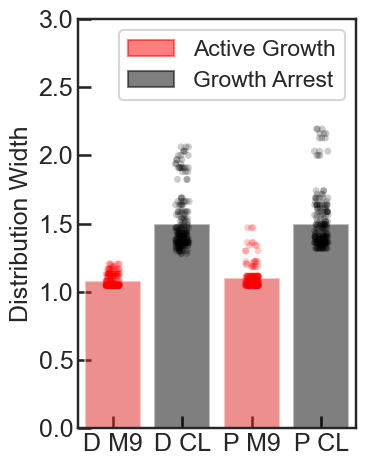

In [16]:
plt.figure(figsize=(4,5))
sns.barplot([stats.gmean(width_ls_M9_D), stats.gmean(width_ls_CL_D),
             stats.gmean(width_ls_M9_P), stats.gmean(width_ls_CL_P)],
            palette=['r','k','r','k'], alpha=0.5,
           legend='brief')
sns.stripplot([width_ls_M9_D, width_ls_CL_D, width_ls_M9_P, width_ls_CL_P],
              palette=['r','k','r','k'], alpha=0.2)
# plt.gca().set_yscale('log')
plt.gca().set_xticklabels(['D M9','D CL', 'P M9', 'P CL'])
plt.ylabel('Distribution Width')
plt.gca().set_ylim((0,3))
# plt.legend(labels=['Active Growth', 'Growth Arrest'])

patches = [mpl.patches.Patch(color='r', alpha=0.5, label='Active Growth'),
          mpl.patches.Patch(color='k', alpha=0.5, label='Growth Arrest')]
plt.legend(handles=patches)

plt.tight_layout()
plt.savefig('./figs/F_P_Noise_Barplot.pdf')
plt.show()


In [17]:
print('Gmeans of distribution widths')
print(stats.gmean(width_ls_M9_D))
print(stats.gmean(width_ls_CL_D))
print(stats.gmean(width_ls_M9_P))
print(stats.gmean(width_ls_CL_P))
print()

print('Shift in distribution width to CL')
print(stats.gmean(width_ls_CL_D)/stats.gmean(width_ls_M9_D))
print(stats.gmean(width_ls_CL_P)/stats.gmean(width_ls_M9_P))

Gmeans of distribution widths
1.081061018911237
1.4942380218450884
1.0980965293202614
1.4977290807904633

Shift in distribution width to CL
1.3821958203154636
1.3639320777359898


## Analysis of BPE-derived parameter estimates

Fig. 5b, 5c

In [27]:
# dCas9:PhlF data

medias = ['M9', 'CL']

data = []
for grna in grnas:
    strand = strand_dict[grna]
    PAM = PAM_dict_DP[grna]
    foldrep_ls = []
    betas_ls = []
    alphas_ls = []
    Ks_ls = []
    ns_ls = []
    for m in range(len(medias)):
        media = medias[m]
        
        filename = './MCMC_outputs/D_'+grna+'_'+media+'_32_10000.pkl'
        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()
        flat_samples = sampler.get_chain(discard=9000, flat=True)
        
        betas = flat_samples[:,0]
        alphas = flat_samples[:,1]
        Ks = flat_samples[:,2]
        ns = flat_samples[:,3]
        foldreps = betas/alphas + 1 # (beta+alpha)/alpha is fold rep.

        foldrep_ls.append(foldreps)
        betas_ls.append(betas)
        alphas_ls.append(alphas)
        Ks_ls.append(Ks)
        ns_ls.append(ns)
        
        for i in range(len(foldreps)):
            data.append([media, PAM, strand, foldreps[i],
                         betas[i], alphas[i],Ks[i], ns[i]])
    
    foldreps_delta = foldrep_ls[1]/foldrep_ls[0]
    betas_delta = betas_ls[1]/betas_ls[0]
    alphas_delta = alphas_ls[1]/alphas_ls[0]
    Ks_delta = Ks_ls[1]/Ks_ls[0]
    ns_delta = ns_ls[1]/ns_ls[0]
    for i in range(len(foldreps_delta)):
        data.append(['Delta', PAM, strand, foldreps_delta[i],
                     betas_delta[i], alphas_delta[i],
                     Ks_delta[i], ns_delta[i]])

params_df_D = pd.DataFrame(data, columns=['Media','Location','Orientation',
                                             'Fold Repression', 'Beta', 'Alpha',
                                             'K', 'n'])

In [28]:
# PhlF data

medias = ['M9', 'CL']

data = []
for grna in grnas:
    strand = strand_dict[grna]
    PAM = PAM_dict_P[grna]
    foldrep_ls = []
    betas_ls = []
    alphas_ls = []
    Ks_ls = []
    ns_ls = []
    for m in range(len(medias)):
        media = medias[m]
        
        filename = './MCMC_outputs/P_'+grna+'_'+media+'_32_10000.pkl'
        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()
        flat_samples = sampler.get_chain(discard=9000, flat=True)
        
        betas = flat_samples[:,0]
        alphas = flat_samples[:,1]
        Ks = flat_samples[:,2]
        ns = flat_samples[:,3]
        foldreps = betas/alphas + 1 # (beta+alpha)/alpha is fold rep.

        foldrep_ls.append(foldreps)
        betas_ls.append(betas)
        alphas_ls.append(alphas)
        Ks_ls.append(Ks)
        ns_ls.append(ns)
        
        for i in range(len(foldreps)):
            data.append([media, PAM, strand, foldreps[i],
                         betas[i], alphas[i],Ks[i], ns[i]])
    
    foldreps_delta = foldrep_ls[1]/foldrep_ls[0]
    betas_delta = betas_ls[1]/betas_ls[0]
    alphas_delta = alphas_ls[1]/alphas_ls[0]
    Ks_delta = Ks_ls[1]/Ks_ls[0]
    ns_delta = ns_ls[1]/ns_ls[0]
    for i in range(len(foldreps_delta)):
        data.append(['Delta', PAM, strand, foldreps_delta[i],
                     betas_delta[i], alphas_delta[i],
                     Ks_delta[i], ns_delta[i]])

params_df_P = pd.DataFrame(data, columns=['Media','Location','Orientation',
                                             'Fold Repression', 'Beta', 'Alpha',
                                             'K', 'n'])

Remove g2 fusion gate data as the gRNA was constructed incorrectly

In [29]:
params_df_D = params_df_D.drop(params_df_D[params_df_D.Location == -33].index)

Set up universal plotting parameters

In [30]:
xmin = -85
xmax = 154
vw_DP = 3.2
vw_P = 2.6

# figure size, in inches
figx = 10
figy = 12
dpi = 300 

### Fusion gates

#### Full plot of BPE parameter distributions

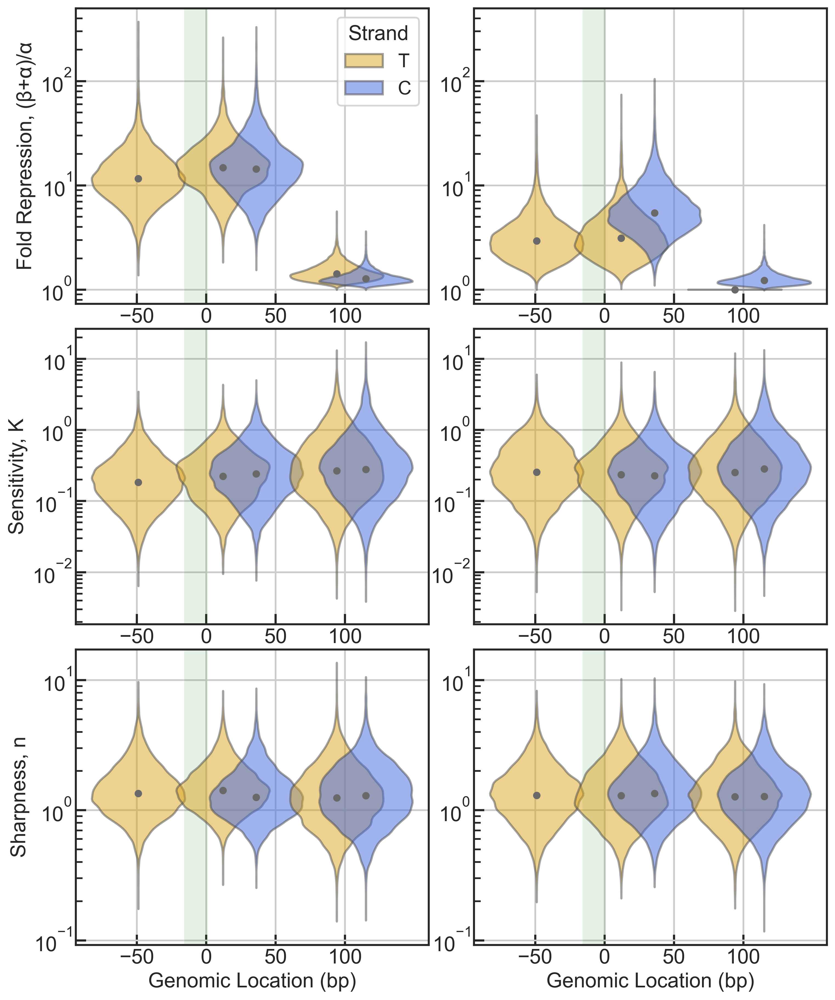

In [31]:
fig = plt.figure(figsize=(figx, figy), dpi=dpi)
ax11 = fig.add_subplot(3, 2, 1)
ax12 = fig.add_subplot(3, 2, 2, sharey=ax11)
ax21 = fig.add_subplot(3, 2, 3)
ax22 = fig.add_subplot(3, 2, 4, sharey=ax21)
ax31 = fig.add_subplot(3, 2, 5)
ax32 = fig.add_subplot(3, 2, 6, sharey=ax31)

# plot T7 promoter window
ax11.axvspan(-16,1, facecolor='g', alpha=0.1)
ax12.axvspan(-16,1, facecolor='g', alpha=0.1)
ax21.axvspan(-16,1, facecolor='g', alpha=0.1)
ax22.axvspan(-16,1, facecolor='g', alpha=0.1)
ax31.axvspan(-16,1, facecolor='g', alpha=0.1)
ax32.axvspan(-16,1, facecolor='g', alpha=0.1)

# M9 plots (left column)
M9df = params_df_D[params_df_D .Media == 'M9']
CLdf = params_df_D[params_df_D .Media == 'CL']

sns.violinplot(data=M9df,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax11,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax21,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax31,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# CL plots (right column)
sns.violinplot(data=CLdf,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax12,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax22,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax32,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# Plot Medians
m9_reps = M9df.groupby('Location')['Fold Repression'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_reps = CLdf.groupby('Location')['Fold Repression'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()



ax11.scatter(np.array(m9_reps.index), np.array(m9_reps), c='dimgrey')
ax21.scatter(np.array(m9_Ks.index), np.array(m9_Ks), c='dimgrey')
ax31.scatter(np.array(m9_ns.index), np.array(m9_ns), c='dimgrey')
ax12.scatter(np.array(cl_reps.index), np.array(cl_reps), c='dimgrey')
ax22.scatter(np.array(cl_Ks.index), np.array(cl_Ks), c='dimgrey')
ax32.scatter(np.array(cl_ns.index), np.array(cl_ns), c='dimgrey')

# ax11.axhline(1, linestyle='--', c='k')
# ax12.axhline(1, linestyle='--', c='k')

ax11.set_ylabel('Fold Repression, (β+α)/α')
ax21.set_ylabel('Sensitivity, K')
ax31.set_ylabel('Sharpness, n')
ax11.set_xlabel('')
ax12.set_xlabel('')
ax21.set_xlabel('')
ax22.set_xlabel('')
ax31.set_xlabel('Genomic Location (bp)')
ax32.set_xlabel('Genomic Location (bp)')
ax12.set_ylabel('')
ax22.set_ylabel('')
ax32.set_ylabel('')

ax11.set_xticks([-50,0,50,100])
ax21.set_xticks([-50,0,50,100])
ax31.set_xticks([-50,0,50,100])
ax12.set_xticks([-50,0,50,100])
ax22.set_xticks([-50,0,50,100])
ax32.set_xticks([-50,0,50,100])
ax11.grid(visible=True)
ax21.grid(visible=True)
ax31.grid(visible=True)
ax12.grid(visible=True)
ax22.grid(visible=True)
ax32.grid(visible=True)

# ax11.legend(title='Strand', labels=['','T','','C'])
# ax11.

handles, labels = ax11.get_legend_handles_labels()
ax11.legend(title='Strand', handles=handles, labels=['T','C'])

plt.tight_layout(pad=0.1)
plt.savefig('./figs/Fgates_BPE_parameters.pdf')
plt.show()

#### Parameter shift analysis and plotting

In [32]:
print(np.array(m9_ns))
print(np.array(cl_ns))
print()
print(np.array(m9_Ks))
print(max(m9_Ks)/min(m9_Ks))
print(np.array(cl_Ks))
print(max(cl_Ks)/min(cl_Ks))
print()
print(np.array(m9_betas))
print(np.array(cl_betas))
print(stats.gmean(m9_betas)/stats.gmean(cl_betas))
print()
print(np.array(m9_reps))

[1.34806136 1.41783498 1.25832108 1.24509045 1.29310791]
[1.30092108 1.29494655 1.3451858  1.26934831 1.27375753]

[0.18411132 0.2240122  0.24161899 0.26738178 0.27890534]
1.5148733789486386
[0.25619856 0.23619016 0.22653606 0.2532284  0.28389041]
1.2531798123933267

[334208.47754472 301481.76295406 322554.87167679 114581.76511845
  56362.72996323]
[2.20434004e+03 1.08014090e+03 1.96621690e+03 1.30650760e-06
 7.90286566e+02]
8463.31558842922

[11.59394645 14.83578257 14.38038867  1.41682177  1.27201101]


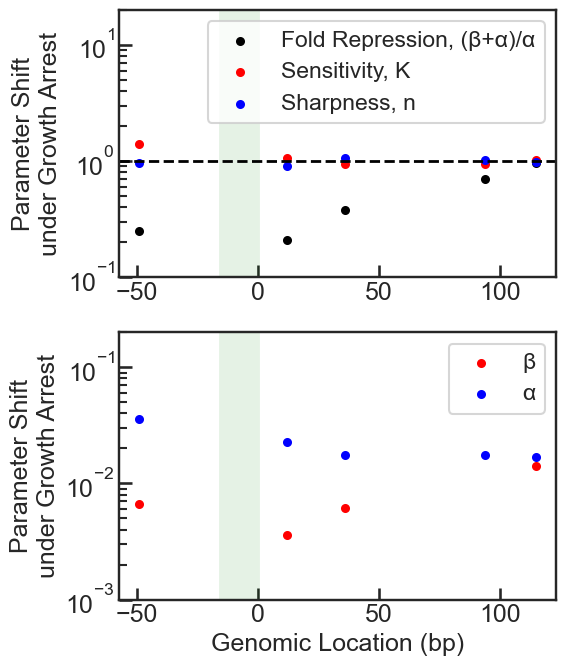

In [33]:
m9_FCs = M9df.groupby('Location')['Fold Repression'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
m9_alphas = M9df.groupby('Location')['Alpha'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_FCs = CLdf.groupby('Location')['Fold Repression'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()
cl_alphas = CLdf.groupby('Location')['Alpha'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()

# calculate delta directly as ratio of medians
delta_FCs = cl_FCs/m9_FCs
delta_Ks = cl_Ks/m9_Ks
delta_ns = cl_ns/m9_ns
delta_betas = cl_betas/m9_betas
delta_alphas = cl_alphas/m9_alphas

fig, ax = plt.subplots(2, 1, figsize=(6,7))
ax[0].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[0].axhline(1, c='k', linestyle='--', lw=2)
ax[0].scatter(np.array(delta_FCs.index), np.array(delta_FCs), label='Fold Repression, (β+α)/α', c='k')
ax[0].scatter(np.array(delta_Ks.index), np.array(delta_Ks), label='Sensitivity, K', c='r')
ax[0].scatter(np.array(delta_ns.index), np.array(delta_ns), label='Sharpness, n', c='b')
ax[0].set_yscale('log')
ax[0].set_ylim((1e-1,2e1))
ax[0].legend()
ax[0].set_ylabel('Parameter Shift\nunder Growth Arrest')

ax[1].axvspan(-16,1, facecolor='g', alpha=0.1)
# ax[1].axhline(1, c='k', linestyle='--', lw=2)
ax[1].scatter(np.array(delta_betas.index), np.array(delta_betas), label='β', c='r')
ax[1].scatter(np.array(delta_alphas.index), np.array(delta_alphas), label='α', c='b')
ax[1].set_yscale('log')
ax[1].set_ylim((1e-3,2e-1))
ax[1].legend()
ax[1].set_xlabel('Genomic Location (bp)')
ax[1].set_ylabel('Parameter Shift\nunder Growth Arrest')
plt.tight_layout()
plt.savefig('./figs/Fgates_BPE_parameter_shifts.pdf')
plt.show()



In [34]:
delta_Ks = np.array(delta_Ks)
delta_FCs = np.array(delta_FCs)
delta_ns = np.array(delta_ns)
delta_betas = np.array(delta_betas)
delta_alphas = np.array(delta_alphas)

# delete the gate that didn't repress
delta_Ks = np.delete(delta_Ks, 3)
delta_FCs = np.delete(delta_FCs, 3)
delta_ns = np.delete(delta_ns, 3)
delta_betas = np.delete(delta_betas, 3)
delta_alphas = np.delete(delta_alphas, 3)

In [35]:

print(delta_Ks)
print(stats.gmean(delta_Ks))
print()
print(delta_FCs)
print(1/stats.gmean(delta_FCs))
print()
print(delta_ns)
print(1/delta_ns)
print(1/stats.gmean(delta_ns))
print()
print(1/stats.gmean(delta_betas))
print(1/stats.gmean(delta_alphas))

[1.39154157 1.05436295 0.93757556 1.01787372]
1.0877939153341365

[0.25289856 0.21081014 0.37949715 0.96440929]
2.675611531288347

[0.96503106 0.9133267  1.06903223 0.98503576]
[1.03623608 1.09489846 0.93542549 1.01519157]
1.0188199468350765

149.1676943887364
45.097952002342495


### PhlF gates

#### Full plot of BPE parameter distributions

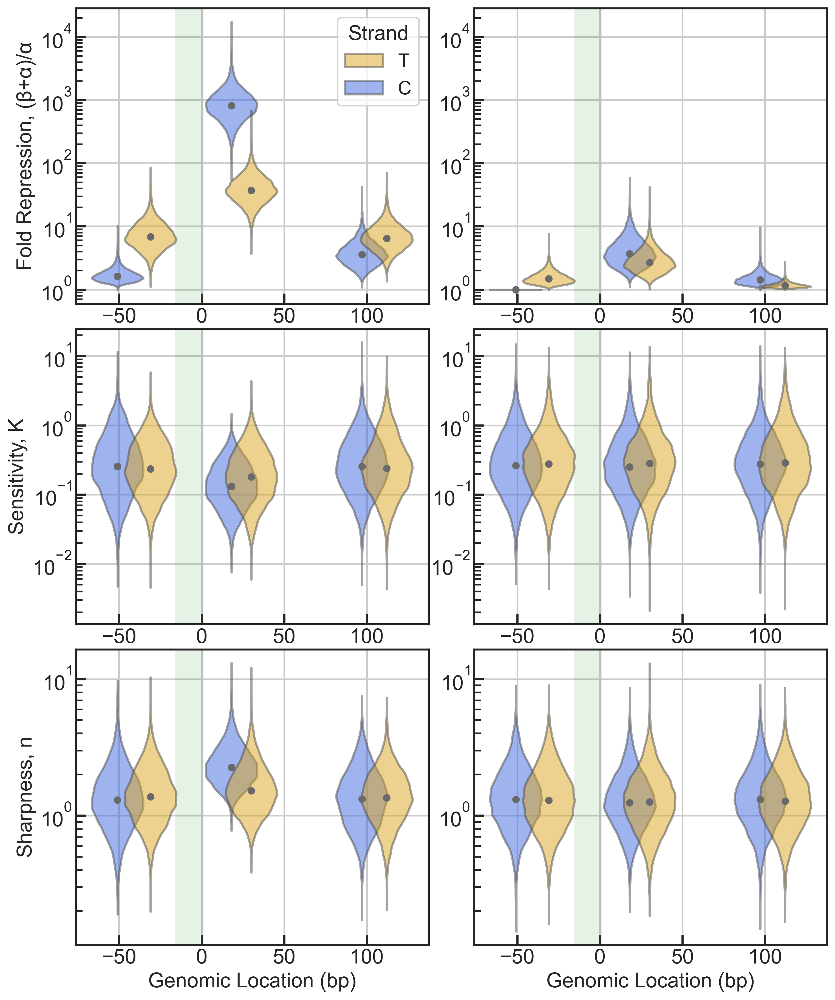

In [36]:
fig = plt.figure(figsize=(figx, figy), dpi=dpi)
ax11 = fig.add_subplot(3, 2, 1)
ax12 = fig.add_subplot(3, 2, 2, sharey=ax11)
ax21 = fig.add_subplot(3, 2, 3)
ax22 = fig.add_subplot(3, 2, 4, sharey=ax21)
ax31 = fig.add_subplot(3, 2, 5)
ax32 = fig.add_subplot(3, 2, 6, sharey=ax31)

# plot T7 promoter window
ax11.axvspan(-16,1, facecolor='g', alpha=0.1)
ax12.axvspan(-16,1, facecolor='g', alpha=0.1)
ax21.axvspan(-16,1, facecolor='g', alpha=0.1)
ax22.axvspan(-16,1, facecolor='g', alpha=0.1)
ax31.axvspan(-16,1, facecolor='g', alpha=0.1)
ax32.axvspan(-16,1, facecolor='g', alpha=0.1)

# M9 plots (left column)
M9df = params_df_P[params_df_P .Media == 'M9']
CLdf = params_df_P[params_df_P .Media == 'CL']

sns.violinplot(data=M9df,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax11,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax21,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax31,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# CL plots (right column)
sns.violinplot(data=CLdf,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax12,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax22,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax32,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# Plot Medians
m9_reps = M9df.groupby('Location')['Fold Repression'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_reps = CLdf.groupby('Location')['Fold Repression'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()

ax11.scatter(np.array(m9_reps.index), np.array(m9_reps), c='dimgrey')
ax21.scatter(np.array(m9_Ks.index), np.array(m9_Ks), c='dimgrey')
ax31.scatter(np.array(m9_ns.index), np.array(m9_ns), c='dimgrey')
ax12.scatter(np.array(cl_reps.index), np.array(cl_reps), c='dimgrey')
ax22.scatter(np.array(cl_Ks.index), np.array(cl_Ks), c='dimgrey')
ax32.scatter(np.array(cl_ns.index), np.array(cl_ns), c='dimgrey')

# ax11.axhline(1, linestyle='--', c='k')
# ax12.axhline(1, linestyle='--', c='k')

ax11.set_ylabel('Fold Repression, (β+α)/α')
ax21.set_ylabel('Sensitivity, K')
ax31.set_ylabel('Sharpness, n')
ax11.set_xlabel('')
ax12.set_xlabel('')
ax21.set_xlabel('')
ax22.set_xlabel('')
ax31.set_xlabel('Genomic Location (bp)')
ax32.set_xlabel('Genomic Location (bp)')
ax12.set_ylabel('')
ax22.set_ylabel('')
ax32.set_ylabel('')

ax11.set_xticks([-50,0,50,100])
ax21.set_xticks([-50,0,50,100])
ax31.set_xticks([-50,0,50,100])
ax12.set_xticks([-50,0,50,100])
ax22.set_xticks([-50,0,50,100])
ax32.set_xticks([-50,0,50,100])
ax11.grid(visible=True)
ax21.grid(visible=True)
ax31.grid(visible=True)
ax12.grid(visible=True)
ax22.grid(visible=True)
ax32.grid(visible=True)

# ax11.legend(title='Strand', labels=['','T','','C'])
# ax11.

handles, labels = ax11.get_legend_handles_labels()
ax11.legend(title='Strand', handles=handles, labels=['T','C'])

plt.tight_layout(pad=0.1)
plt.savefig('./figs/Pgates_BPE_parameters.pdf')
plt.show()

#### Parameter shift analysis and plotting

In [37]:
print(np.array(m9_ns))
print(np.array(cl_ns))
print()
print(np.array(m9_Ks))
print(max(m9_Ks)/min(m9_Ks))
print(np.array(cl_Ks))
print(max(cl_Ks)/min(cl_Ks))
print()
print(np.array(m9_betas))
print(np.array(cl_betas))
print(stats.gmean(m9_betas[1:])/stats.gmean(cl_betas[1:]))

[1.30115827 1.37656168 2.25917273 1.52402505 1.32472435 1.35312303]
[1.31362086 1.29758754 1.24245816 1.25969101 1.31069259 1.28020523]

[0.2556278  0.23502731 0.1319918  0.1812425  0.25574611 0.23997281]
1.9375908562700765
[0.26340711 0.27779928 0.25166022 0.28224796 0.27843492 0.28936238]
1.1498137465547524

[135616.95330566 315161.82666748 336180.62730191 303274.97825553
 247774.34000823 301872.14155032]
[1.28787774e-06 1.00938465e+03 1.37084151e+03 1.85261947e+03
 1.76867222e+03 6.09972179e+02]
244.23445826734647


In [38]:
print(np.array(m9_reps))

[  1.62808319   6.85789553 820.12552055  37.3370575    3.58223424
   6.47958815]


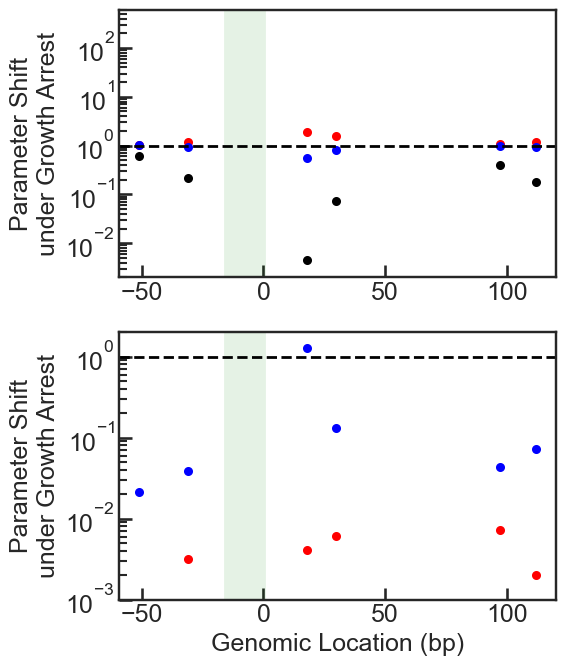

In [39]:
m9_FCs = M9df.groupby('Location')['Fold Repression'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
m9_alphas = M9df.groupby('Location')['Alpha'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_FCs = CLdf.groupby('Location')['Fold Repression'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()
cl_alphas = CLdf.groupby('Location')['Alpha'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()

# calculate delta directly as ratio of medians
delta_FCs = cl_FCs/m9_FCs
delta_Ks = cl_Ks/m9_Ks
delta_ns = cl_ns/m9_ns
delta_betas = cl_betas/m9_betas
delta_alphas = cl_alphas/m9_alphas

fig, ax = plt.subplots(2, 1, figsize=(6,7))
ax[0].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[0].axhline(1, c='k', linestyle='--', lw=2)
ax[0].scatter(np.array(delta_FCs.index), np.array(delta_FCs), label='Fold Repression, (β+α)/α', c='k')
ax[0].scatter(np.array(delta_Ks.index), np.array(delta_Ks), label='Sensitivity, K', c='r')
ax[0].scatter(np.array(delta_ns.index), np.array(delta_ns), label='Sharpness, n', c='b')
ax[0].set_yscale('log')
ax[0].set_ylim((2e-3,6e2))
# ax[0].legend()
ax[0].set_ylabel('Parameter Shift\nunder Growth Arrest')

ax[1].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[1].axhline(1, c='k', linestyle='--', lw=2)
ax[1].scatter(np.array(delta_betas.index), np.array(delta_betas), label='β', c='r')
ax[1].scatter(np.array(delta_alphas.index), np.array(delta_alphas), label='α', c='b')
ax[1].set_yscale('log')
ax[1].set_ylim((1e-3,2e0))
# ax[1].legend()
ax[1].set_xlabel('Genomic Location (bp)')
ax[1].set_ylabel('Parameter Shift\nunder Growth Arrest')
plt.tight_layout()
plt.savefig('./figs/Pgates_BPE_parameter_shifts.pdf')
plt.show()



In [40]:
delta_Ks = np.array(delta_Ks)
delta_FCs = np.array(delta_FCs)
delta_ns = np.array(delta_ns)
delta_betas = np.array(delta_betas)
delta_alphas = np.array(delta_alphas)

# delete the gate that didn't repress
delta_Ks = np.delete(delta_Ks, 0)
delta_FCs = np.delete(delta_FCs, 0)
delta_ns = np.delete(delta_ns, 0)
delta_betas = np.delete(delta_betas, 0)
delta_alphas = np.delete(delta_alphas, 0)

In [41]:

print(delta_Ks)
print(stats.gmean(delta_Ks))
print()
print(delta_FCs)
print(1/stats.gmean(delta_FCs))
print()
print(delta_ns)
print(1/delta_ns)
print(1/stats.gmean(delta_ns))
print()
print(1/stats.gmean(delta_betas))
print(1/stats.gmean(delta_alphas))

[1.18198722 1.90663525 1.55729459 1.08871615 1.20581321]
1.3573416510007674

[0.21624023 0.00448258 0.07209805 0.39780079 0.17789727]
11.512121210577853

[0.94262942 0.54996156 0.82655532 0.98940778 0.94611148]
[1.06086228 1.81830889 1.20984037 1.01070561 1.0569579 ]
1.2004592503181442

244.23445826734647
8.754829802259597
